# BHC Faster R-CNN — optimized training notebook

Uses the SAME Roboflow workspace/project/version and API key from the uploaded notebook. Training uses Faster R-CNN ResNet-50 FPN v2 for the same two classes.

Optimizations: multi-GPU DataParallel with a loss wrapper, mixed precision on CUDA, pinned memory, persistent data-loader workers, larger batch size, per-epoch checkpointing, automatic resume, loss graphs, and the existing evaluation/prediction cells.

**Kaggle requirement:** Enable the accelerator in Notebook Settings (GPU, and select 2 GPUs if the option is available). Python code cannot turn on a GPU that Kaggle has not assigned. This notebook uses every GPU reported by `torch.cuda.device_count()`; if only one is assigned, it uses one.

**Recovery:** Checkpoints in `/kaggle/working` are session-local until saved/downloaded as notebook output. Download `fasterrcnn_resume.pth` or save a version before the session ends. The old epoch-93 weights were not saved, so the first run starts from COCO-pretrained weights.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for name in files:
        if 'fasterrcnn_resume' in name.lower():
            print(os.path.join(root, name))

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CUDA available: True


In [3]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for name in files:
        if name == 'fasterrcnn_resume.pth':
            path = os.path.join(root, name)
            print("Checkpoint:", path)
            print("Size (MB):", round(os.path.getsize(path) / (1024**2), 2))

In [2]:
import os

from google.colab import drive
drive.mount('/content/drive')

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for name in files:
        if name in [
            "fasterrcnn_resume.pth",
            "fasterrcnn_beach_human.pth",
            "history.json"
        ]:
            path = os.path.join(root, name)
            print(f"FOUND: {path}")
            print(f"Size: {os.path.getsize(path) / (1024**2):.2f} MB")


Mounted at /content/drive


In [5]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for name in files:
        if name in [
            'fasterrcnn_resume.pth',
            'fasterrcnn_beach_human.pth',
            'history.json',
            'loss_curve.png',
            'loss_components.png'
        ]:
            path = os.path.join(root, name)
            print(f"FOUND: {path}")
            print(f"SIZE: {os.path.getsize(path) / (1024**2):.2f} MB")
            print("-" * 50)

In [6]:
import os

base = "/content/drive/MyDrive"

print("MyDrive contents:")
for item in os.listdir(base):
    path = os.path.join(base, item)
    kind = "FOLDER" if os.path.isdir(path) else "FILE"
    print(f"{kind}: {item}")

MyDrive contents:
FOLDER: Classroom
FOLDER: Class 10 marksheet and migration certificate 
FOLDER: clg
FOLDER: Scl memr
FOLDER: Important files
FOLDER: Colab Notebooks
FILE: Mr.Beast Feastables .gdoc
FILE: MR.Beast Feastables.gslides
FILE: Monthly budget.gsheet
FILE: expenses.gsheet
FILE: 4 elements restaurent.zip
FILE: viva.gdoc
FILE: CB.SC.U4CSE23711   SET-2 PART-B.gdoc
FILE: 23711 conditional sattements.docx
FILE: 23711 loops.docx
FILE: 23711 print f scan f.docx
FILE: 23MAT116_lab_manual[1] (1)_copy.pdf
FILE: 23711 (1).pdf
FILE: Copy of 23711.pdf
FILE: Copy of Copy of 23711.pdf
FILE: 711 c lang.gdoc
FILE: dsa h02.pdf
FILE: 23711.pdf
FILE: Untitled spreadsheet (2).gsheet
FILE: boat 1 p.mp4
FILE: ooty reel 1.mp4
FILE: Electronic Voting Machine (EVM) Synchronization.gslides
FILE: Neural-Networks-main.zip
FILE: payment.jpg
FILE: BHARGAVA RAM KAZA_Resume (4).pdf
FILE: BHARGAVA RAM KAZA_Resume (3).pdf
FILE: BHARGAVA RAM KAZA_Resume (2).pdf
FILE: BHARGAVA RAM KAZA_Resume (1).pdf
FILE: BHARG

In [7]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for folder in dirs:
        if "fasterrcnn" in folder.lower() or "checkpoint" in folder.lower():
            print("FOLDER:", os.path.join(root, folder))

FOLDER: /content/drive/MyDrive/fasterrcnn_resume.pth
FOLDER: /content/drive/MyDrive/bhc/checkpoints_150_epochs


In [8]:
import os

folders = [
    "/content/drive/MyDrive/Faster_RCNN_Beach_Results",
    "/content/drive/MyDrive/fasterrcnn_resume.pth",
    "/content/drive/MyDrive/bhc/checkpoints_150_epochs"
]

for folder in folders:
    print(f"\n{'='*60}\nFOLDER: {folder}")
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            level = root.replace(folder, "").count(os.sep)
            if level > 3:
                dirs[:] = []
                continue
            print("  " * level + os.path.basename(root) + "/")
            for name in files[:20]:
                path = os.path.join(root, name)
                size = os.path.getsize(path) / (1024**2)
                print("  " * (level + 1) + f"{name} ({size:.2f} MB)")
    else:
        print("Folder not found")


FOLDER: /content/drive/MyDrive/Faster_RCNN_Beach_Results
Faster_RCNN_Beach_Results/
  test_predictions/
    test_prediction_01.png (2.07 MB)
    test_prediction_02.png (1.93 MB)
    test_prediction_03.png (1.89 MB)
    test_prediction_04.png (1.84 MB)
    test_prediction_05.png (1.81 MB)
    test_prediction_06.png (1.70 MB)
    test_prediction_07.png (1.59 MB)
    test_prediction_08.png (1.37 MB)
    test_prediction_09.png (1.35 MB)
    test_prediction_10.png (1.40 MB)

FOLDER: /content/drive/MyDrive/fasterrcnn_resume.pth
fasterrcnn_resume.pth/
  data.pkl (0.08 MB)
  .format_version (0.00 MB)
  .storage_alignment (0.00 MB)
  byteorder (0.00 MB)
  version (0.00 MB)
  data/
    0 (0.04 MB)
    1 (0.00 MB)
    2 (0.00 MB)
    3 (0.00 MB)
    4 (0.00 MB)
    5 (0.00 MB)
    6 (0.02 MB)
    7 (0.00 MB)
    8 (0.00 MB)
    9 (0.00 MB)
    10 (0.00 MB)
    11 (0.00 MB)
    12 (0.14 MB)
    13 (0.00 MB)
    14 (0.00 MB)
    15 (0.00 MB)
    16 (0.00 MB)
    17 (0.00 MB)
    18 (0.06 MB)
    1

In [9]:
import os
import zipfile

source_dir = "/content/drive/MyDrive/fasterrcnn_resume.pth"
output_file = "/content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth"

assert os.path.isfile(os.path.join(source_dir, "data.pkl")), \
    "data.pkl was not found in the checkpoint folder"

with zipfile.ZipFile(output_file, "w", compression=zipfile.ZIP_STORED) as z:
    for root, dirs, files in os.walk(source_dir):
        for name in files:
            path = os.path.join(root, name)
            relative = os.path.relpath(path, source_dir)
            archive_path = os.path.join("checkpoint", relative).replace("\\", "/")
            z.write(path, archive_path)

print("Rebuilt checkpoint:", output_file)
print("Size:", round(os.path.getsize(output_file) / (1024**2), 2), "MB")

Rebuilt checkpoint: /content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth
Size: 329.57 MB


In [10]:
import torch

checkpoint_path = "/content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth"

try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )
    print("Checkpoint loaded successfully.")
    print("Object type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Available keys:", list(checkpoint.keys()))

except Exception as e:
    print("Checkpoint loading failed:")
    print(type(e).__name__, str(e))

Checkpoint loaded successfully.
Object type: <class 'dict'>
Available keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'history']


In [11]:
import torch

checkpoint_path = "/content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Saved epoch:", checkpoint["epoch"])
print("History type:", type(checkpoint["history"]))

history = checkpoint["history"]

if isinstance(history, dict):
    for key, value in history.items():
        print(f"\n{key}:")
        print(value[:5] if isinstance(value, list) else value)
        if isinstance(value, list):
            print("Number of entries:", len(value))
elif isinstance(history, list):
    print("Number of entries:", len(history))
    print("First entry:", history[:2])
else:
    print(history)

Saved epoch: 50
History type: <class 'dict'>

train_loss:
[0.39921785909257035, 0.23480595877810104, 0.19760302293054088, 0.17677710752409462, 0.13915521387503657]
Number of entries: 50

val_loss:
[0.2962419718341983, 0.25549178758393165, 0.232932966092156, 0.24557422038835838, 0.21761073975661852]
Number of entries: 50

loss_classifier:
[0.09097041649777007, 0.047071155642282196, 0.03878367426338355, 0.034128178112553954, 0.028128744844940542]
Number of entries: 50

loss_box_reg:
[0.1878760029576, 0.11572816716400708, 0.09766500656904303, 0.08821675688179616, 0.0659518886117033]
Number of entries: 50

loss_objectness:
[0.03411566908766757, 0.014919149290491368, 0.011917056591157816, 0.010389521425509552, 0.008891006001817336]
Number of entries: 50

loss_rpn_box_reg:
[0.08625576918889168, 0.057087486642022824, 0.049237285413957194, 0.04404265128746351, 0.036183574378607454]
Number of entries: 50


In [12]:
import matplotlib.pyplot as plt
import os

history = checkpoint["history"]
print("Available history fields:", list(history.keys()))

Available history fields: ['train_loss', 'val_loss', 'loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg']


In [4]:
from google.colab import drive
import os

drive.mount('/content/drive')

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for name in files:
        if name in [
            'fasterrcnn_beach_human.pth',
            'history.json',
            'loss_curve.png',
            'loss_components.png'
        ]:
            path = os.path.join(root, name)
            print(path, f"({os.path.getsize(path) / (1024**2):.2f} MB)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

for base in ["/kaggle/input", "/kaggle/working"]:
    print(f"\nSearching {base}...")
    for root, dirs, files in os.walk(base):
        for name in files:
            if (
                "resume" in name.lower()
                or name.endswith(".pth")
                or name.endswith(".pt")
            ):
                path = os.path.join(root, name)
                print(
                    "FOUND:",
                    path,
                    f"| Size: {os.path.getsize(path) / (1024**2):.2f} MB"
                )


Searching /kaggle/input...

Searching /kaggle/working...


In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for name in files:
        print(os.path.join(root, name))

/kaggle/working/.virtual_documents/__notebook_source__.ipynb


In [ ]:
!pip install -q roboflow torchmetrics pycocotools albumentations


In [ ]:
from roboflow import Roboflow
import os

rf = Roboflow(api_key="XslFaDHQ2fu2uFnuAF5K")
project = rf.workspace("image-analysis-project-rfnyq").project("human-coastal-zmajf")
version = project.version(1)
dataset = version.download("yolov8")

LOCAL_DATASET_PATH = dataset.location
DATASET_PATH = LOCAL_DATASET_PATH
DATASET_DRIVE_PATH = '/kaggle/working/fasterrcnn_training'
os.makedirs(DATASET_DRIVE_PATH, exist_ok=True)
print("Dataset downloaded to:", LOCAL_DATASET_PATH)
print(os.listdir(LOCAL_DATASET_PATH))


In [ ]:
import yaml

with open(os.path.join(LOCAL_DATASET_PATH, "data.yaml")) as f:
    data_yaml = yaml.safe_load(f)

print(data_yaml)
CLASS_NAMES_RAW = {i: name for i, name in enumerate(data_yaml['names'])}
print("Classes:", CLASS_NAMES_RAW)

In [ ]:
from PIL import Image
import torch
from torch.utils.data import Dataset
import torchvision.transforms.functional as F

RAW_TO_MODEL = {0: 1, 1: 2}   # torchvision reserves label 0 for background
MODEL_TO_RAW = {1: 0, 2: 1}
NUM_CLASSES_WITH_BG = 3

class YoloDetectionDataset(Dataset):
    def __init__(self, split_dir, transforms=None):
        self.images_dir = os.path.join(split_dir, "images")
        self.labels_dir = os.path.join(split_dir, "labels")
        self.transforms = transforms
        self.image_files = sorted([
            f for f in os.listdir(self.images_dir)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.images_dir, img_name)
        label_path = os.path.join(self.labels_dir, os.path.splitext(img_name)[0] + ".txt")

        img = Image.open(img_path).convert("RGB")
        img_w, img_h = img.size

        boxes, labels = [], []
        if os.path.exists(label_path):
            with open(label_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) != 5:
                        continue
                    cls, xc, yc, w, h = parts
                    cls = int(cls)
                    xc, yc, w, h = float(xc), float(yc), float(w), float(h)

                    x1 = (xc - w / 2) * img_w
                    y1 = (yc - h / 2) * img_h
                    x2 = (xc + w / 2) * img_w
                    y2 = (yc + h / 2) * img_h

                    if x2 <= x1 or y2 <= y1:
                        continue

                    boxes.append([x1, y1, x2, y2])
                    labels.append(RAW_TO_MODEL[cls])

        boxes = torch.as_tensor(boxes, dtype=torch.float32) if boxes else torch.zeros((0, 4), dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64) if labels else torch.zeros((0,), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx]),
            "area": (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0]) if len(boxes) else torch.zeros((0,)),
            "iscrowd": torch.zeros((len(boxes),), dtype=torch.int64),
        }

        img = F.to_tensor(img)
        if self.transforms:
            img, target = self.transforms(img, target)
        return img, target

def collate_fn(batch):
    return tuple(zip(*batch))

In [ ]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def get_model(num_classes=NUM_CLASSES_WITH_BG):
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn_v2(weights="DEFAULT")
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

model = get_model()
model.to(device)

In [ ]:
from torch.utils.data import DataLoader
import os
import torch

TRAIN_DIR = os.path.join(LOCAL_DATASET_PATH, "train")
VALID_DIR = os.path.join(LOCAL_DATASET_PATH, "valid")
TEST_DIR  = os.path.join(LOCAL_DATASET_PATH, "test")

train_dataset = YoloDetectionDataset(TRAIN_DIR)
valid_dataset = YoloDetectionDataset(VALID_DIR)
test_dataset  = YoloDetectionDataset(TEST_DIR)

print("Train:", len(train_dataset), " Valid:", len(valid_dataset), " Test:", len(test_dataset))

# Batch size is split across the GPUs by DataParallel.
# With 2 GPUs, batch size 4 means roughly 2 images per GPU.
BATCH_SIZE = 2
NUM_WORKERS = min(4, os.cpu_count() or 2)
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, collate_fn=collate_fn,
    pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0
)
valid_loader = DataLoader(
    valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, collate_fn=collate_fn,
    pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, collate_fn=collate_fn,
    pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0
)

img, target = train_dataset[0]
print("Sample image shape:", img.shape, "target keys:", list(target.keys()))


In [ ]:
import os
import json
import time
import torch
import matplotlib.pyplot as plt

NUM_EPOCHS = 50

os.makedirs(DATASET_DRIVE_PATH, exist_ok=True)

CKPT_PATH = os.path.join(DATASET_DRIVE_PATH, "fasterrcnn_resume.pth")
MODEL_PATH = os.path.join(DATASET_DRIVE_PATH, "fasterrcnn_beach_human.pth")
HISTORY_PATH = os.path.join(DATASET_DRIVE_PATH, "history.json")
LOSS_GRAPH_PATH = os.path.join(DATASET_DRIVE_PATH, "loss_curve.png")
COMPONENT_GRAPH_PATH = os.path.join(DATASET_DRIVE_PATH, "loss_components.png")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Available GPUs:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Use a single GPU. Do not wrap this detection model in DataParallel.
if isinstance(model, torch.nn.DataParallel):
    model = model.module

model = model.to(device)
train_model = model

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=4,
    gamma=0.1
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

history = {
    "train_loss": [],
    "val_loss": [],
    "loss_classifier": [],
    "loss_box_reg": [],
    "loss_objectness": [],
    "loss_rpn_box_reg": []
}

start_epoch = 0

# Restore the most recent saved checkpoint.
if os.path.isfile(CKPT_PATH):
    checkpoint = torch.load(
        CKPT_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    lr_scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    if "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

    history = checkpoint.get("history", history)
    start_epoch = int(checkpoint["epoch"])

    print(f"Resuming after epoch {start_epoch}.")
else:
    print("No checkpoint found. Starting with the current model weights.")

def calculate_validation_loss(detector, data_loader):
    # Torchvision detection models return loss dictionaries in training mode.
    detector.train()
    total_loss = 0.0
    batch_count = 0

    with torch.no_grad():
        for images, targets in data_loader:
            images = [
                image.to(device, non_blocking=True)
                for image in images
            ]

            targets = [
                {
                    key: value.to(device, non_blocking=True)
                    if torch.is_tensor(value) else value
                    for key, value in target.items()
                }
                for target in targets
            ]

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                loss_dict = detector(images, targets)
                loss = sum(loss_dict.values())

            total_loss += loss.item()
            batch_count += 1

    return total_loss / max(batch_count, 1)

for epoch in range(start_epoch, NUM_EPOCHS):
    model.train()

    total_loss = 0.0
    batch_count = 0

    component_totals = {
        "loss_classifier": 0.0,
        "loss_box_reg": 0.0,
        "loss_objectness": 0.0,
        "loss_rpn_box_reg": 0.0
    }

    start_time = time.time()

    for images, targets in train_loader:
        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        targets = [
            {
                key: value.to(device, non_blocking=True)
                if torch.is_tensor(value) else value
                for key, value in target.items()
            }
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            loss_dict = train_model(images, targets)
            loss = sum(loss_dict.values())

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite training loss at epoch {epoch + 1}: "
                f"{loss.item()}"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.detach().item()
        batch_count += 1

        for key in component_totals:
            if key in loss_dict:
                component_totals[key] += loss_dict[key].detach().item()

    train_loss = total_loss / max(batch_count, 1)

    for key in component_totals:
        component_totals[key] /= max(batch_count, 1)

    val_loss = calculate_validation_loss(model, valid_loader)

    # Restore training mode for the next epoch.
    model.train()
    lr_scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    for key in component_totals:
        history[key].append(component_totals[key])

    completed_epoch = epoch + 1
    elapsed_minutes = (time.time() - start_time) / 60

    print(
        f"Epoch {completed_epoch}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Time: {elapsed_minutes:.2f} min"
    )

    # Save a resumable checkpoint after each completed epoch.
    checkpoint_state = {
        "epoch": completed_epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": lr_scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history
    }

    temp_path = CKPT_PATH + ".tmp"
    torch.save(checkpoint_state, temp_path)
    os.replace(temp_path, CKPT_PATH)

    torch.save(model.state_dict(), MODEL_PATH)

    with open(HISTORY_PATH, "w") as history_file:
        json.dump(history, history_file)

    # Save training and validation loss graph.
    plt.figure(figsize=(9, 5))
    plt.plot(history["train_loss"], label="Training Loss")
    plt.plot(history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Faster R-CNN Training and Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(LOSS_GRAPH_PATH, dpi=180)
    plt.close()

    # Save individual loss component graph.
    plt.figure(figsize=(10, 6))

    for key in component_totals:
        plt.plot(history[key], label=key)

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Faster R-CNN Loss Components")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(COMPONENT_GRAPH_PATH, dpi=180)
    plt.close()

print("Training loop completed.")
print("Model saved at:", MODEL_PATH)
print("Checkpoint saved at:", CKPT_PATH)
print("History saved at:", HISTORY_PATH)
print("Loss graph saved at:", LOSS_GRAPH_PATH)
print("Component graph saved at:", COMPONENT_GRAPH_PATH)

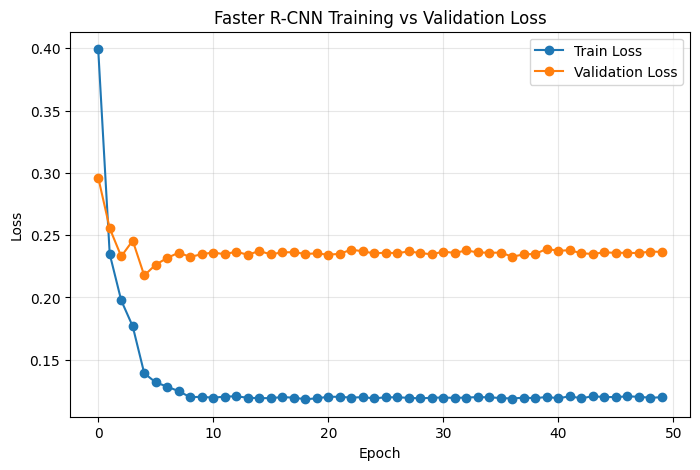

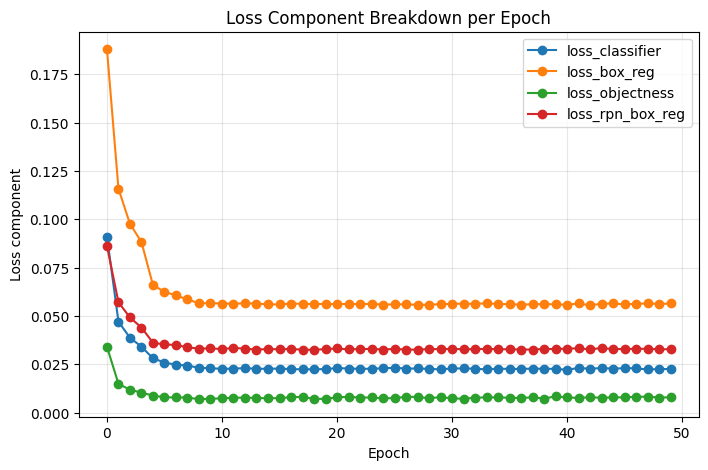

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history["train_loss"], label="Train Loss", marker='o')
plt.plot(history["val_loss"], label="Validation Loss", marker='o')
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Faster R-CNN Training vs Validation Loss")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("/content/loss_curve.png", dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8,5))
for k in ["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]:
    plt.plot(history[k], label=k, marker='o')
plt.xlabel("Epoch"); plt.ylabel("Loss component"); plt.title("Loss Component Breakdown per Epoch")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("/content/loss_components.png", dpi=150, bbox_inches='tight')
plt.show()

In [15]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = "/content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model = fasterrcnn_resnet50_fpn_v2(
    weights=None,
    weights_backbone=None,
    num_classes=3
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Model loaded successfully.")
print("Saved epoch:", checkpoint["epoch"])
print("Device:", device)

Model loaded successfully.
Saved epoch: 50
Device: cpu


In [19]:
import os

base = "/content/drive/MyDrive/bhc"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    if level > 3:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for f in files[:8]:
        print("  " * (level + 1) + f)

bhc/
  README.roboflow.txt
  README.dataset.txt
  data.yaml
  test/
    labels/
      1640133905-Wed-Dec-22_10_45_05-AEST-2021-BURLEIGH-TWR-snap-4Gtrailcam_jpg.rf.b0419103eeb747c4412114c9da3d39c1.txt
      1640382303-Sat-Dec-25_07_45_03-AEST-2021-BURLEIGH-TWR-snap-4Gtrailcam_jpg.rf.e852ecbc5c8de9720ba57339a51d2156.txt
      1640385905-Sat-Dec-25_08_45_05-AEST-2021-BURLEIGH-TWR-snap-4Gtrailcam_jpg.rf.7fc7b2049c5263f79183c31675878b50.txt
      1640151902-Wed-Dec-22_15_45_02-AEST-2021-BURLEIGH-TWR-snap-4Gtrailcam_jpg.rf.bb684fdd8a4dae4c4bb446d9c49bfc2f.txt
      1640154603-Wed-Dec-22_16_30_03-AEST-2021-BURLEIGH-TWR-snap-4Gtrailcam_jpg.rf.5ad1e5e90bf2f8d5aa2d9f607c3e1144.txt
      1640142002-Wed-Dec-22_13_00_02-AEST-2021-BURLEIGH-TWR-snap-4Gtrailcam_jpg.rf.844da89706dfb956fbe5c73717e7321a.txt
      1640139304-Wed-Dec-22_12_15_04-AEST-2021-BURLEIGH-TWR-snap-4Gtrailcam_jpg.rf.b8647a4b7ec995085f701c9ce4ced2fb.txt
      1640395802-Sat-Dec-25_11_30_02-AEST-2021-BURLEIGH-TWR-snap-4Gtrailcam_jpg.

In [20]:
data_yaml = "/content/drive/MyDrive/bhc/data.yaml"

with open(data_yaml, "r") as f:
    print(f.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['0', '1']

roboflow:
  workspace: image-analysis-project-rfnyq
  project: human-coastal-zmajf
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/image-analysis-project-rfnyq/human-coastal-zmajf/dataset/1


In [21]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F

class BeachTestDataset(Dataset):
    def __init__(self, root):
        self.image_dir = os.path.join(root, "test", "images")
        self.label_dir = os.path.join(root, "test", "labels")
        self.images = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        filename = self.images[idx]
        image_path = os.path.join(self.image_dir, filename)
        label_path = os.path.join(
            self.label_dir, os.path.splitext(filename)[0] + ".txt"
        )

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        boxes, labels = [], []

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) != 5:
                        continue

                    cls, xc, yc, bw, bh = map(float, parts)
                    x1 = (xc - bw / 2) * width
                    y1 = (yc - bh / 2) * height
                    x2 = (xc + bw / 2) * width
                    y2 = (yc + bh / 2) * height

                    if x2 > x1 and y2 > y1:
                        boxes.append([x1, y1, x2, y2])
                        labels.append(int(cls) + 1)

        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([idx])
        }

        return F.to_tensor(image), target

def collate_fn(batch):
    return tuple(zip(*batch))

dataset_root = "/content/drive/MyDrive/bhc"
test_dataset = BeachTestDataset(dataset_root)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

print("Test images:", len(test_dataset))

Test images: 114


In [5]:
import os

base = "/content/drive/MyDrive/bhc"

print("Does bhc exist?", os.path.exists(base))

for root, dirs, files in os.walk(base):
    for folder in dirs:
        if folder.lower() == "images":
            print("Images folder:", os.path.join(root, folder))

    if "data.yaml" in files:
        print("Dataset YAML:", os.path.join(root, "data.yaml"))

Does bhc exist? False


In [6]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "data.yaml" in files and os.path.basename(root) == "bhc":
        print("DATASET ROOT:", root)
        print("CONTENTS:", os.listdir(root))

In [9]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="XslFaDHQ2fu2uFnuAF5K")
project = rf.workspace("image-analysis-project-rfnyq").project("human-coastal-zmajf")
version = project.version(1)
dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.8 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to human-coastal-1 in yolov8:: 100%|██████████| 2267/2267 [00:05<00:00, 406.64it/s] 


In [10]:
print(dataset.location)

/content/human-coastal-1


In [11]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F

dataset_root = dataset.location
print("Dataset root:", dataset_root)
print("Contents:", os.listdir(dataset_root))

class BeachTestDataset(Dataset):
    def __init__(self, root):
        self.image_dir = os.path.join(root, "test", "images")
        self.label_dir = os.path.join(root, "test", "labels")

        if not os.path.isdir(self.image_dir):
            raise FileNotFoundError(
                f"Test images folder not found: {self.image_dir}"
            )

        self.images = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        filename = self.images[idx]
        image = Image.open(
            os.path.join(self.image_dir, filename)
        ).convert("RGB")

        width, height = image.size
        label_path = os.path.join(
            self.label_dir, os.path.splitext(filename)[0] + ".txt"
        )

        boxes, labels = [], []

        if os.path.exists(label_path):
            with open(label_path) as f:
                for line in f:
                    values = line.split()
                    if len(values) != 5:
                        continue

                    cls, xc, yc, bw, bh = map(float, values)

                    x1 = max(0, (xc - bw / 2) * width)
                    y1 = max(0, (yc - bh / 2) * height)
                    x2 = min(width, (xc + bw / 2) * width)
                    y2 = min(height, (yc + bh / 2) * height)

                    if x2 > x1 and y2 > y1:
                        boxes.append([x1, y1, x2, y2])
                        labels.append(int(cls) + 1)

        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([idx])
        }

        return F.to_tensor(image), target

def collate_fn(batch):
    return tuple(zip(*batch))

test_dataset = BeachTestDataset(dataset_root)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

print("Test images:", len(test_dataset))

Dataset root: /content/human-coastal-1
Contents: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']
Test images: 114


In [20]:
import os

from google.colab import drive
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

search_roots = [
    "/content/drive/MyDrive",
    "/content"
]

for base in search_roots:
    if not os.path.exists(base):
        continue

    for root, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if d != ".cache"]

        for name in files:
            if name in [
                "fasterrcnn_resume_rebuilt.pth",
                "fasterrcnn_resume.pth",
                "fasterrcnn_beach_human.pth"
            ]:
                path = os.path.join(root, name)
                print("FOUND:", path)
                print("SIZE:", round(os.path.getsize(path) / (1024**2), 2), "MB")

Mounted at /content/drive
FOUND: /content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth
SIZE: 329.57 MB
FOUND: /content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth
SIZE: 329.57 MB


In [21]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2

checkpoint_path = "/content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model = fasterrcnn_resnet50_fpn_v2(
    weights=None,
    weights_backbone=None,
    num_classes=3
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Model loaded successfully!")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Device:", device)

Model loaded successfully!
Checkpoint epoch: 50
Device: cuda


In [22]:
model.eval()
all_preds, all_targets = [], []

with torch.no_grad():
    for images, targets in test_loader:
        images = [img.to(device) for img in images]
        outputs = model(images)

        preds = [{k: v.cpu() for k, v in o.items()} for o in outputs]
        tgts = [{k: v.cpu() for k, v in t.items()} for t in targets]

        all_preds.extend(preds)
        all_targets.extend(tgts)

print("Collected predictions for", len(all_preds), "test images")

Collected predictions for 114 test images


In [23]:
history = checkpoint["history"]

print("History type:", type(history))

if isinstance(history, dict):
    for key, value in history.items():
        print(
            key,
            "| epochs:", len(value) if isinstance(value, list) else "N/A",
            "| first values:", value[:5] if isinstance(value, list) else value
        )
elif isinstance(history, list):
    print("Number of entries:", len(history))
    print("First entries:", history[:2])

History type: <class 'dict'>
train_loss | epochs: 50 | first values: [0.39921785909257035, 0.23480595877810104, 0.19760302293054088, 0.17677710752409462, 0.13915521387503657]
val_loss | epochs: 50 | first values: [0.2962419718341983, 0.25549178758393165, 0.232932966092156, 0.24557422038835838, 0.21761073975661852]
loss_classifier | epochs: 50 | first values: [0.09097041649777007, 0.047071155642282196, 0.03878367426338355, 0.034128178112553954, 0.028128744844940542]
loss_box_reg | epochs: 50 | first values: [0.1878760029576, 0.11572816716400708, 0.09766500656904303, 0.08821675688179616, 0.0659518886117033]
loss_objectness | epochs: 50 | first values: [0.03411566908766757, 0.014919149290491368, 0.011917056591157816, 0.010389521425509552, 0.008891006001817336]
loss_rpn_box_reg | epochs: 50 | first values: [0.08625576918889168, 0.057087486642022824, 0.049237285413957194, 0.04404265128746351, 0.036183574378607454]


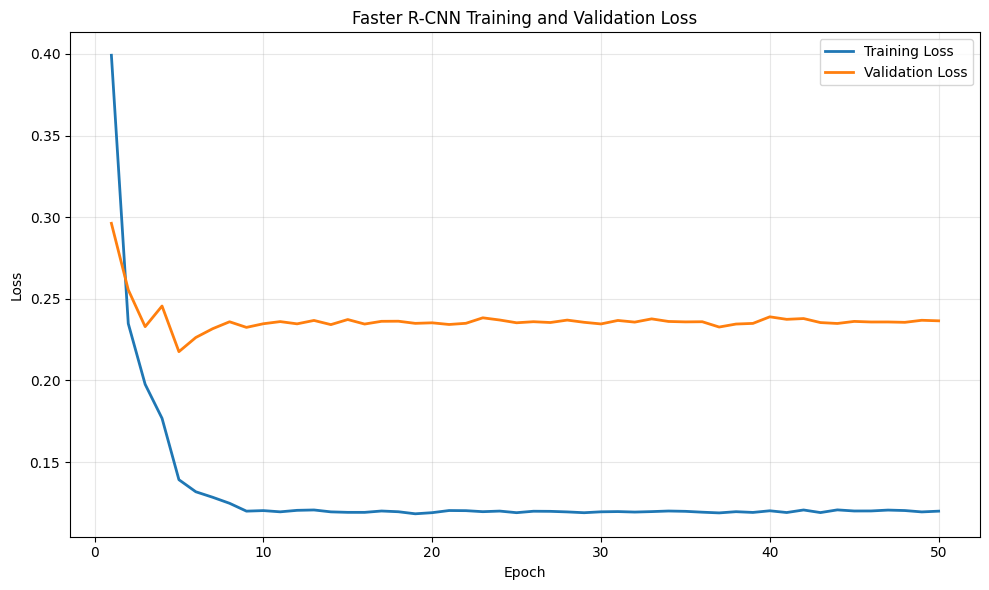

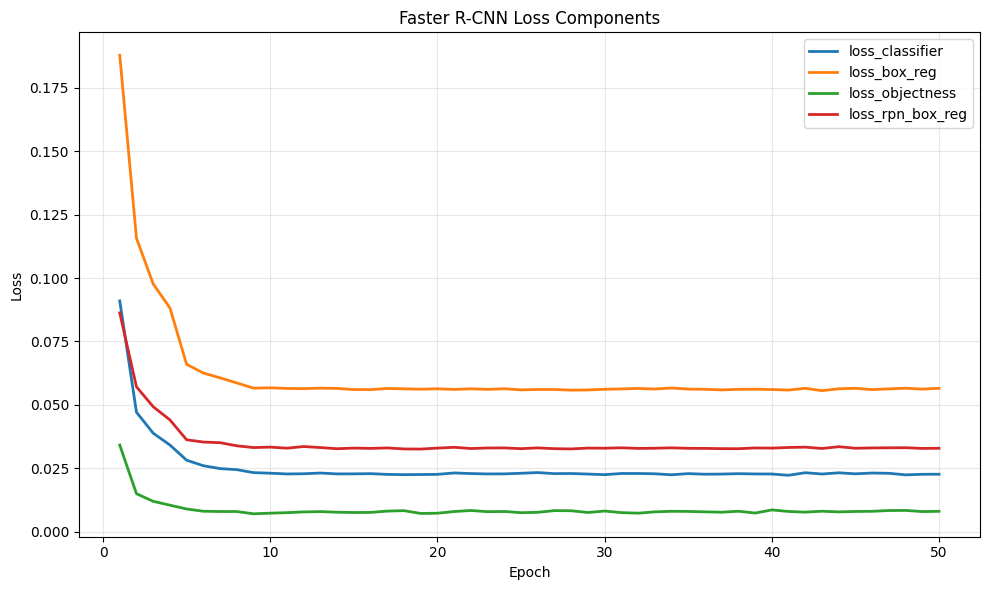

Graphs saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs
Training epochs: 50
Final training loss: 0.1199
Final validation loss: 0.2365


In [25]:
import os
import matplotlib.pyplot as plt
import numpy as np

history = checkpoint["history"]

output_dir = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
os.makedirs(output_dir, exist_ok=True)

epochs = np.arange(1, len(history["train_loss"]) + 1)

# Training vs validation loss
plt.figure(figsize=(10, 6))
plt.plot(epochs, history["train_loss"], label="Training Loss", linewidth=2)
plt.plot(epochs, history["val_loss"], label="Validation Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Faster R-CNN Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "loss_curve.png"), dpi=300)
plt.show()

# Individual loss components
components = [
    "loss_classifier",
    "loss_box_reg",
    "loss_objectness",
    "loss_rpn_box_reg"
]

plt.figure(figsize=(10, 6))
for key in components:
    plt.plot(epochs, history[key], label=key, linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Faster R-CNN Loss Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "loss_components.png"), dpi=300)
plt.show()

print("Graphs saved to:", output_dir)
print("Training epochs:", len(epochs))
print("Final training loss:", round(history["train_loss"][-1], 4))
print("Final validation loss:", round(history["val_loss"][-1], 4))

In [29]:
import torch
from torchvision.ops import box_iou

def calculate_metrics(predictions, targets, iou_threshold=0.5, score_threshold=0.5):
    tp = fp = fn = 0

    for pred, target in zip(predictions, targets):
        keep = pred["scores"] >= score_threshold
        boxes = pred["boxes"][keep]
        labels = pred["labels"][keep]

        gt_boxes = target["boxes"]
        gt_labels = target["labels"]
        matched = set()

        if len(boxes) > 0 and len(gt_boxes) > 0:
            ious = box_iou(boxes, gt_boxes)
        else:
            ious = torch.zeros((len(boxes), len(gt_boxes)))

        order = torch.argsort(pred["scores"][keep], descending=True)

        for i in order.tolist():
            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched and labels[i].item() == gt_labels[j].item()
            ]

            if candidates:
                best = max(candidates, key=lambda j: ious[i, j].item())

                if ious[i, best].item() >= iou_threshold:
                    tp += 1
                    matched.add(best)
                else:
                    fp += 1
            else:
                fp += 1

        fn += len(gt_boxes) - len(matched)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

metrics = calculate_metrics(all_preds, all_targets)

for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{key}: {value}")

True Positives: 1660
False Positives: 108
False Negatives: 357
Precision: 0.9389 (93.89%)
Recall: 0.8230 (82.30%)
F1-score: 0.8771 (87.71%)


In [30]:
import os
import torch
import json
import numpy as np
import matplotlib.pyplot as plt
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2

from google.colab import drive

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = "/content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth"

assert os.path.isfile(checkpoint_path), f"Checkpoint not found: {checkpoint_path}"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model = fasterrcnn_resnet50_fpn_v2(
    weights=None,
    weights_backbone=None,
    num_classes=3
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

history = checkpoint["history"]

output_dir = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
os.makedirs(output_dir, exist_ok=True)

print("Model loaded successfully")
print("Checkpoint epoch:", checkpoint["epoch"])
print("History epochs:", len(history["train_loss"]))
print("Device:", device)
print("Output directory:", output_dir)

Model loaded successfully
Checkpoint epoch: 50
History epochs: 50
Device: cuda
Output directory: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs


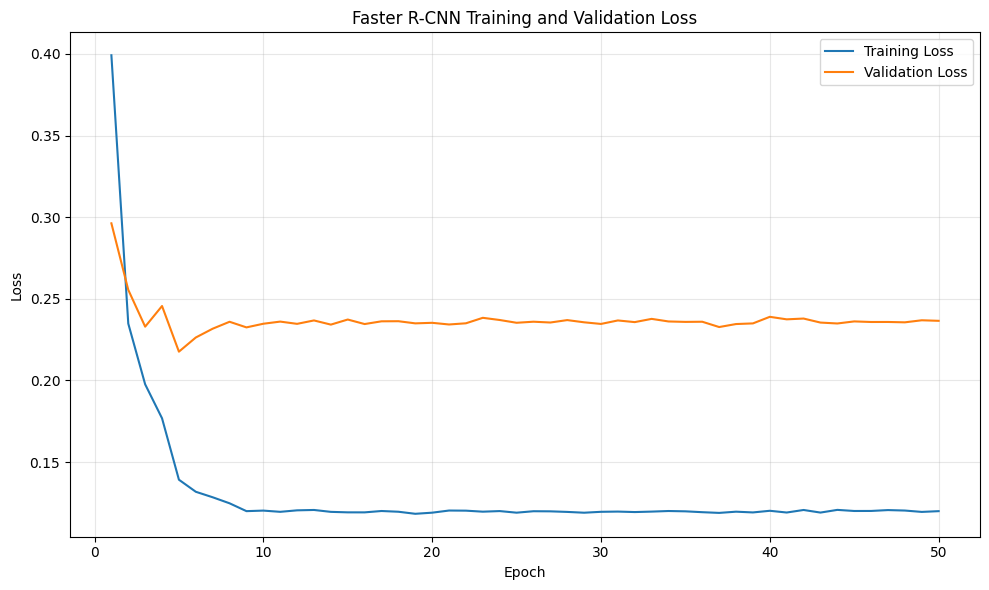

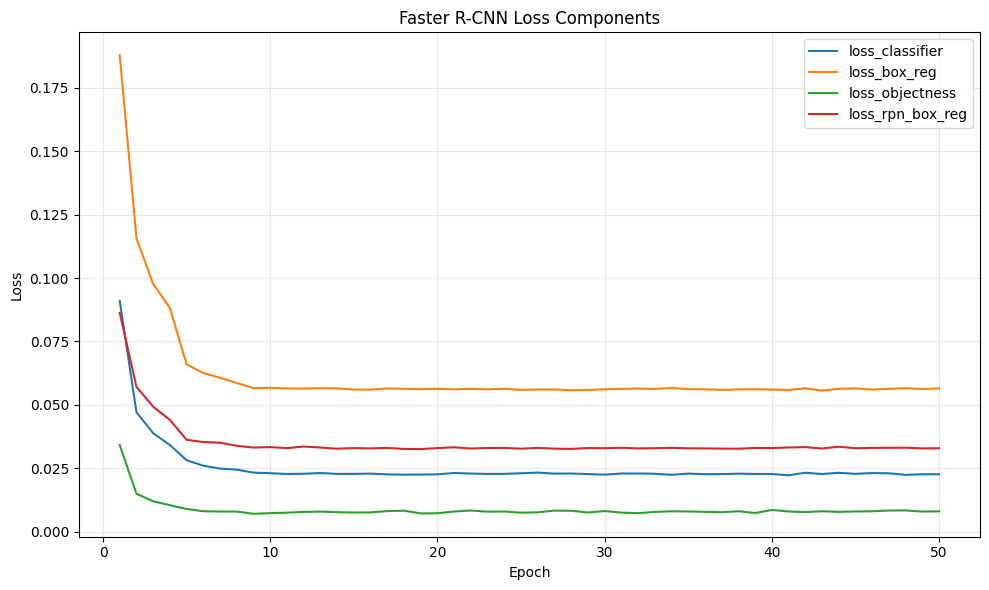

Final training loss: 0.1199
Final validation loss: 0.2365
Graphs saved: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs


In [31]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 6))
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Faster R-CNN Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "loss_curve.png"), dpi=300)
plt.show()

components = [
    "loss_classifier",
    "loss_box_reg",
    "loss_objectness",
    "loss_rpn_box_reg"
]

plt.figure(figsize=(10, 6))
for key in components:
    plt.plot(epochs, history[key], label=key)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Faster R-CNN Loss Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "loss_components.png"), dpi=300)
plt.show()

print("Final training loss:", round(history["train_loss"][-1], 4))
print("Final validation loss:", round(history["val_loss"][-1], 4))
print("Graphs saved:", output_dir)

In [32]:
import os

if "dataset" in globals() and hasattr(dataset, "location"):
    dataset_root = dataset.location
    print("Using existing dataset:", dataset_root)
else:
    from roboflow import Roboflow

    rf = Roboflow(api_key=os.environ.get("ROBOFLOW_API_KEY", ""))
    project = rf.workspace("image-analysis-project-rfnyq").project("human-coastal-zmajf")
    version = project.version(1)
    dataset = version.download("yolov8")
    dataset_root = dataset.location
    print("Dataset downloaded to:", dataset_root)

print("Dataset contents:", os.listdir(dataset_root))

Using existing dataset: /content/human-coastal-1
Dataset contents: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']


In [33]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import to_tensor

class BeachTestDataset(Dataset):
    def __init__(self, root):
        self.image_dir = os.path.join(root, "test", "images")
        self.label_dir = os.path.join(root, "test", "labels")

        if not os.path.isdir(self.image_dir):
            raise FileNotFoundError(
                f"Test image directory not found: {self.image_dir}"
            )

        self.images = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        filename = self.images[idx]
        image = Image.open(
            os.path.join(self.image_dir, filename)
        ).convert("RGB")

        width, height = image.size
        label_path = os.path.join(
            self.label_dir, os.path.splitext(filename)[0] + ".txt"
        )

        boxes, labels = [], []

        if os.path.isfile(label_path):
            with open(label_path) as f:
                for line in f:
                    values = line.strip().split()
                    if len(values) != 5:
                        continue

                    cls, xc, yc, bw, bh = map(float, values)

                    x1 = max(0, (xc - bw / 2) * width)
                    y1 = max(0, (yc - bh / 2) * height)
                    x2 = min(width, (xc + bw / 2) * width)
                    y2 = min(height, (yc + bh / 2) * height)

                    if x2 > x1 and y2 > y1:
                        boxes.append([x1, y1, x2, y2])
                        labels.append(int(cls) + 1)

        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([idx])
        }

        return to_tensor(image), target

def collate_fn(batch):
    return tuple(zip(*batch))

test_dataset = BeachTestDataset(dataset_root)
test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

print("Test images:", len(test_dataset))

Test images: 114


In [34]:
model.eval()
all_preds, all_targets = [], []

with torch.no_grad():
    for images, targets in test_loader:
        images = [img.to(device) for img in images]
        outputs = model(images)

        all_preds.extend([
            {k: v.detach().cpu() for k, v in pred.items()}
            for pred in outputs
        ])
        all_targets.extend([
            {k: v.detach().cpu() for k, v in target.items()}
            for target in targets
        ])

print("Predictions generated:", len(all_preds))
print("Ground-truth annotations collected:", len(all_targets))

Predictions generated: 114
Ground-truth annotations collected: 114


In [35]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from torchvision.transforms.functional import to_pil_image

prediction_dir = os.path.join(output_dir, "predictions")
os.makedirs(prediction_dir, exist_ok=True)

class_names = {
    1: "Human on land",
    2: "Human in water"
}

score_threshold = 0.5
num_images = min(20, len(all_preds))

for idx in range(num_images):
    image, _ = test_dataset[idx]
    img = to_pil_image(image)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img)

    pred = all_preds[idx]

    for box, label, score in zip(
        pred["boxes"], pred["labels"], pred["scores"]
    ):
        if score.item() < score_threshold:
            continue

        x1, y1, x2, y2 = box.tolist()
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="lime", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, max(0, y1 - 5),
            f'{class_names.get(label.item(), str(label.item()))}: {score.item():.2f}',
            color="white", fontsize=9,
            bbox=dict(facecolor="black", alpha=0.7)
        )

    ax.axis("off")
    fig.savefig(
        os.path.join(prediction_dir, f"prediction_{idx+1:03d}.png"),
        bbox_inches="tight", dpi=150
    )
    plt.close(fig)

print(f"Saved {num_images} prediction images to {prediction_dir}")

Saved 20 prediction images to /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/predictions


In [36]:
from torchvision.ops import box_iou

def calculate_metrics(predictions, targets, iou_threshold=0.5,
                      score_threshold=0.5):
    tp = fp = fn = 0

    for pred, target in zip(predictions, targets):
        keep = pred["scores"] >= score_threshold
        boxes = pred["boxes"][keep]
        labels = pred["labels"][keep]

        gt_boxes = target["boxes"]
        gt_labels = target["labels"]
        matched = set()

        ious = (
            box_iou(boxes, gt_boxes)
            if len(boxes) and len(gt_boxes)
            else torch.zeros((len(boxes), len(gt_boxes)))
        )

        scores = pred["scores"][keep]
        for i in torch.argsort(scores, descending=True).tolist():
            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched
                and labels[i].item() == gt_labels[j].item()
            ]

            if candidates:
                best = max(candidates, key=lambda j: ious[i, j].item())
                if ious[i, best].item() >= iou_threshold:
                    tp += 1
                    matched.add(best)
                else:
                    fp += 1
            else:
                fp += 1

        fn += len(gt_boxes) - len(matched)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    return {
        "TP": tp, "FP": fp, "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

metrics = calculate_metrics(all_preds, all_targets)

for name, value in metrics.items():
    print(f"{name}: {value:.4f}" if isinstance(value, float)
          else f"{name}: {value}")

TP: 1660
FP: 108
FN: 357
Precision: 0.9389
Recall: 0.8230
F1-score: 0.8771


In [37]:
import json
import shutil

results = {
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "test_images": len(all_preds),
    "final_train_loss": float(history["train_loss"][-1]),
    "final_val_loss": float(history["val_loss"][-1]),
    "metrics": {
        key: float(value) if isinstance(value, (int, float)) else value
        for key, value in metrics.items()
    }
}

results_path = os.path.join(output_dir, "evaluation_results.json")

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("Results saved to:", results_path)

{
    "checkpoint_epoch": 50,
    "test_images": 114,
    "final_train_loss": 0.1198857512867532,
    "final_val_loss": 0.23650612096281964,
    "metrics": {
        "TP": 1660.0,
        "FP": 108.0,
        "FN": 357.0,
        "Precision": 0.9389140271493213,
        "Recall": 0.8230044620723848,
        "F1-score": 0.8771466314398945
    }
}
Results saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/evaluation_results.json


In [38]:
!pip install -q torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 15.1 MB/s eta 0:00:00


In [39]:
import torch
from torchmetrics.detection.mean_ap import MeanAveragePrecision

map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.50]  # mAP@0.50
)

map_50_95_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox"
)

predictions = []
targets = []

for pred, target in zip(all_preds, all_targets):
    predictions.append({
        "boxes": pred["boxes"].float(),
        "scores": pred["scores"].float(),
        "labels": pred["labels"].int()
    })

    targets.append({
        "boxes": target["boxes"].float(),
        "labels": target["labels"].int()
    })

map_metric.update(predictions, targets)
map_50_95_metric.update(predictions, targets)

result_50 = map_metric.compute()
result_50_95 = map_50_95_metric.compute()

print(f"mAP@0.50: {result_50['map']:.4f}")
print(f"mAP@0.50:0.95: {result_50_95['map']:.4f}")
print(f"mAP@0.50:0.95 (percentage): {result_50_95['map'] * 100:.2f}%")

mAP@0.50: 0.8534
mAP@0.50:0.95: 0.6902
mAP@0.50:0.95 (percentage): 69.02%


In [40]:
import os
import json

map_results = {
    "mAP@0.50": float(result_50["map"]),
    "mAP@0.50:0.95": float(result_50_95["map"]),
    "mAR@0.50:0.95": float(result_50_95["mar_100"])
}

results_path = os.path.join(
    output_dir, "map_evaluation_results.json"
)

with open(results_path, "w") as f:
    json.dump(map_results, f, indent=4)

print(json.dumps(map_results, indent=4))
print("Saved to:", results_path)

{
    "mAP@0.50": 0.8533799052238464,
    "mAP@0.50:0.95": 0.690197229385376,
    "mAR@0.50:0.95": 0.7348071932792664
}
Saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/map_evaluation_results.json


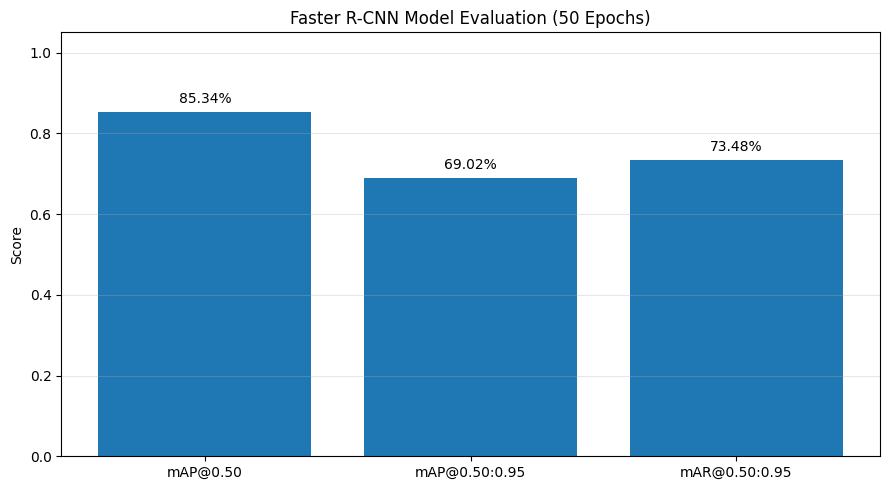

Graph saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/final_evaluation_metrics.png


In [41]:

import matplotlib.pyplot as plt
import numpy as np
import os

output_dir = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
os.makedirs(output_dir, exist_ok=True)

metrics = ["mAP@0.50", "mAP@0.50:0.95", "mAR@0.50:0.95"]
values = [0.8533799, 0.6901972, 0.7348072]

plt.figure(figsize=(9, 5))
bars = plt.bar(metrics, values)

plt.ylabel("Score")
plt.title("Faster R-CNN Model Evaluation (50 Epochs)")
plt.ylim(0, 1.05)
plt.bar_label(bars, labels=[f"{v*100:.2f}%" for v in values], padding=4)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "final_evaluation_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Graph saved to:", os.path.join(output_dir, "final_evaluation_metrics.png"))


In [42]:

import os

output_dir = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"

for root, dirs, files in os.walk(output_dir):
    for file in sorted(files):
        path = os.path.join(root, file)
        print(f"{file}  ({os.path.getsize(path) / 1024:.1f} KB)")


evaluation_results.json  (0.3 KB)
final_evaluation_metrics.png  (88.1 KB)
loss_components.png  (181.1 KB)
loss_curve.png  (141.1 KB)
map_evaluation_results.json  (0.1 KB)
prediction_001.png  (1426.6 KB)
prediction_002.png  (1335.1 KB)
prediction_003.png  (1298.4 KB)
prediction_004.png  (1262.5 KB)
prediction_005.png  (1239.5 KB)
prediction_006.png  (1172.3 KB)
prediction_007.png  (1128.3 KB)
prediction_008.png  (961.6 KB)
prediction_009.png  (943.3 KB)
prediction_010.png  (1001.9 KB)
prediction_011.png  (1002.6 KB)
prediction_012.png  (1004.4 KB)
prediction_013.png  (1047.2 KB)
prediction_014.png  (1085.6 KB)
prediction_015.png  (1193.4 KB)
prediction_016.png  (1226.6 KB)
prediction_017.png  (1273.9 KB)
prediction_018.png  (1405.9 KB)
prediction_019.png  (1410.5 KB)
prediction_020.png  (1081.8 KB)
prediction_021.png  (1087.5 KB)
prediction_022.png  (1440.0 KB)
prediction_023.png  (1436.2 KB)
prediction_024.png  (1230.7 KB)
prediction_025.png  (1243.0 KB)
prediction_026.png  (1152.6 KB)

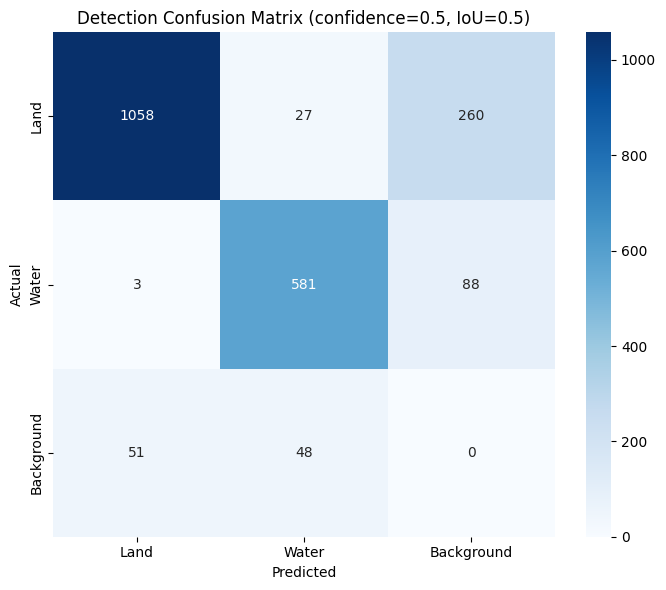


Detection metrics:
mAP@0.50: 0.8534 (85.34%)
mAR@0.5: 0.8695 (86.95%)
mAP@0.75: 0.7986 (79.86%)
mAR@0.75: 0.8222 (82.22%)
mAP@0.50:0.95: 0.6902 (69.02%)
mAR@0.50:0.95: 0.7348 (73.48%)


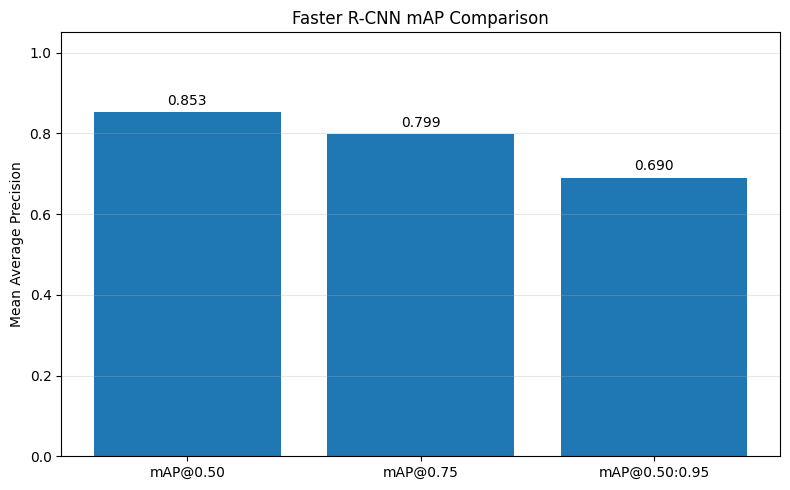


Class-wise AP:
Class  mAP@0.50  mAP@0.75  mAP@0.50:0.95
 Land    0.8156    0.7754         0.7008
Water    0.8912    0.8218         0.6796


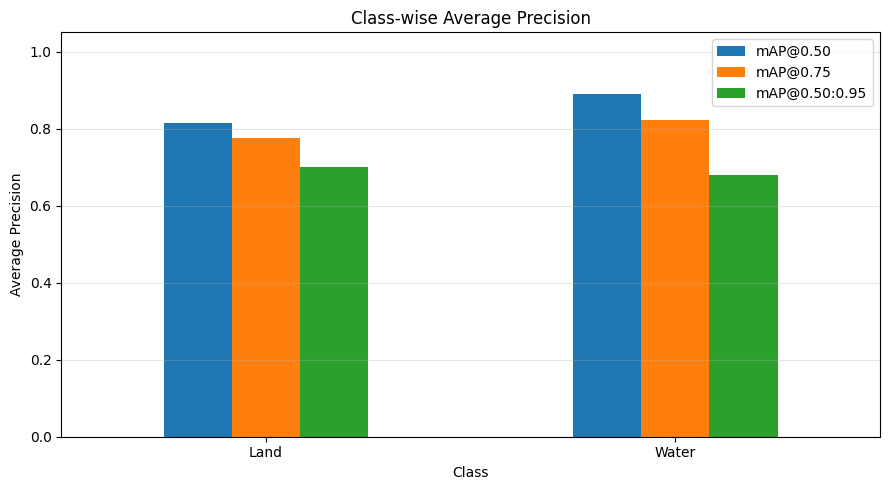

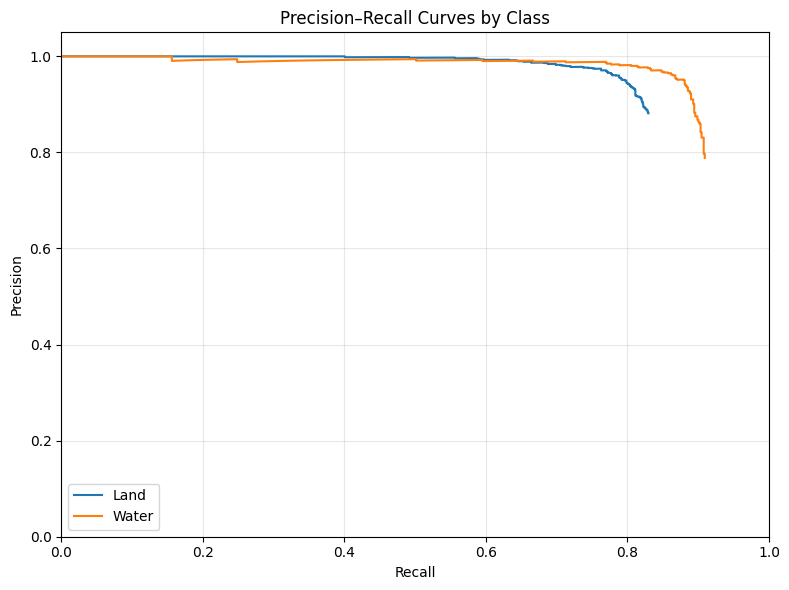

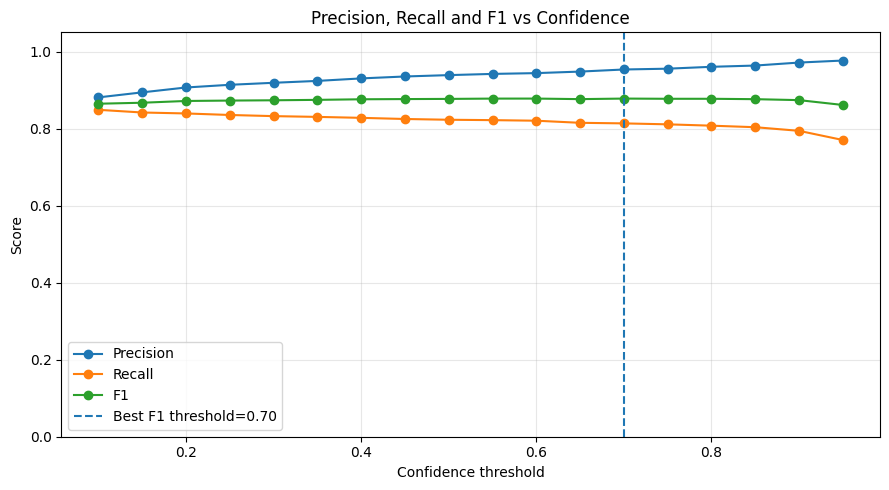


Class-wise metrics at confidence 0.50:
class  precision  recall     F1   TP  FP  FN
 Land     0.9550  0.7896 0.8645 1062  50 283
Water     0.9116  0.8899 0.9006  598  58  74


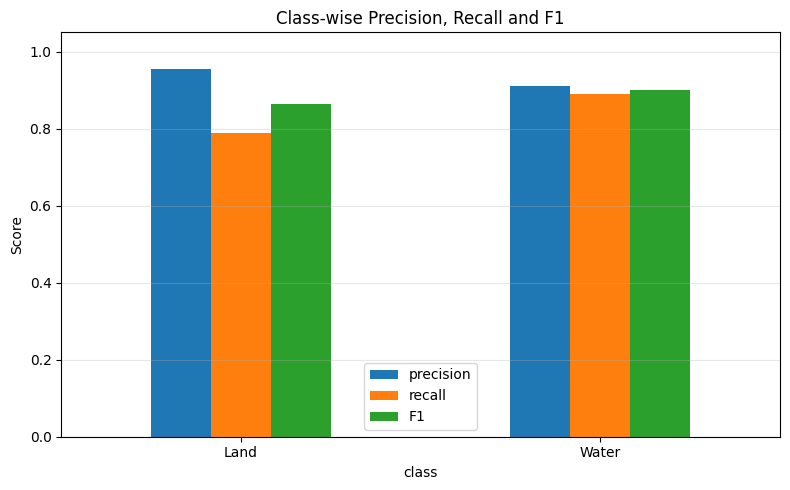

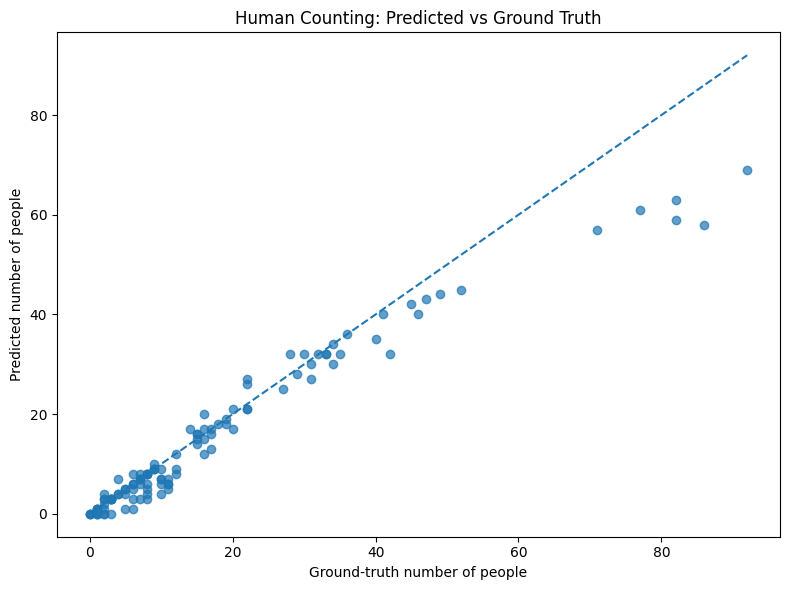

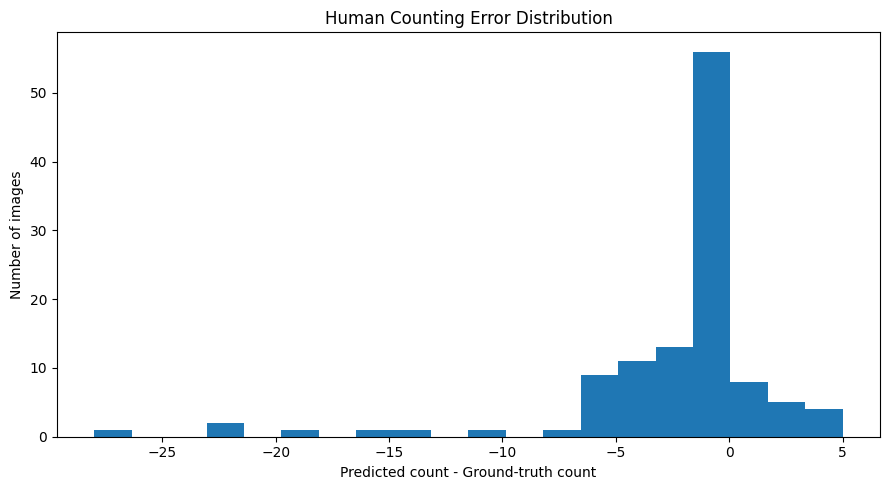


Inference speed: {'timed_images': 114, 'total_inference_seconds': 23.152576516999943, 'milliseconds_per_image': 203.0927764649118, 'images_per_second': 4.923858038706608}

Human counting MAE: 2.8333
Human counting RMSE: 5.5131

All remaining outputs saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs

Files generated:
 - class_wise_AP.csv
 - class_wise_AP.png
 - class_wise_precision_recall_f1.csv
 - class_wise_precision_recall_f1.png
 - confidence_threshold_curve.png
 - confidence_threshold_metrics.csv
 - confusion_matrix.csv
 - confusion_matrix.png
 - evaluation_results.json
 - final_evaluation_metrics.png
 - human_count_error_distribution.png
 - human_count_scatter.png
 - loss_components.png
 - loss_curve.png
 - map_evaluation_results.json
 - map_threshold_comparison.png
 - per_image_human_counts.csv
 - precision_recall_by_class.png
 - prediction_001.png
 - prediction_002.png
 - prediction_003.png
 - prediction_004.png
 - prediction_005.png
 - prediction_006.png
 - predictio

In [43]:

# Remaining Faster R-CNN evaluation outputs
# Uses existing predictions; does NOT retrain the model.

!pip install -q torchmetrics pycocotools

import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torchvision.ops import box_iou
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from sklearn.metrics import mean_absolute_error, mean_squared_error

OUT = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
os.makedirs(OUT, exist_ok=True)

CLASS_NAMES = {1: "Land", 2: "Water"}
CONF = 0.50
IOU = 0.50

# Prepare predictions and targets on CPU
preds, targets = [], []

for p, t in zip(all_preds, all_targets):
    preds.append({
        "boxes": p["boxes"].detach().cpu().float(),
        "scores": p["scores"].detach().cpu().float(),
        "labels": p["labels"].detach().cpu().long()
    })
    targets.append({
        "boxes": t["boxes"].detach().cpu().float(),
        "labels": t["labels"].detach().cpu().long()
    })

assert len(preds) == len(targets) and len(preds) > 0

# =====================================================
# 1. CONFUSION MATRIX: Land, Water, Background
# =====================================================
cm = np.zeros((3, 3), dtype=int)

for p, t in zip(preds, targets):
    keep = p["scores"] >= CONF
    pb, pl = p["boxes"][keep], p["labels"][keep]
    gb, gl = t["boxes"], t["labels"]

    matched_p, matched_g = set(), set()

    if len(pb) and len(gb):
        overlaps = box_iou(gb, pb)
        pairs = [
            (float(overlaps[g, j]), g, j)
            for g in range(len(gb))
            for j in range(len(pb))
            if overlaps[g, j] >= IOU
        ]
        pairs.sort(reverse=True)

        for overlap, g, j in pairs:
            if g in matched_g or j in matched_p:
                continue
            actual, predicted = int(gl[g]), int(pl[j])
            if actual in (1, 2) and predicted in (1, 2):
                cm[actual-1, predicted-1] += 1
            matched_g.add(g)
            matched_p.add(j)

    for g in range(len(gb)):
        if g not in matched_g and int(gl[g]) in (1, 2):
            cm[int(gl[g])-1, 2] += 1

    for j in range(len(pb)):
        if j not in matched_p and int(pl[j]) in (1, 2):
            cm[2, int(pl[j])-1] += 1

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Land", "Water", "Background"],
    yticklabels=["Land", "Water", "Background"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Detection Confusion Matrix (confidence={CONF}, IoU={IOU})")
plt.tight_layout()
plt.savefig(f"{OUT}/confusion_matrix.png", dpi=300)
plt.show()
np.savetxt(f"{OUT}/confusion_matrix.csv", cm, delimiter=",", fmt="%d")

# =====================================================
# 2. mAP@0.50, mAP@0.75, mAP@0.50:0.95 AND CLASS AP
# =====================================================
metric_specs = {
    "mAP@0.50": [0.50],
    "mAP@0.75": [0.75],
    "mAP@0.50:0.95": list(np.arange(0.50, 0.96, 0.05))
}

map_results = {}
per_class_results = {}

for metric_name, iou_thresholds in metric_specs.items():
    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        iou_thresholds=iou_thresholds,
        class_metrics=True
    )
    metric.update(preds, targets)
    result = metric.compute()

    map_results[metric_name] = float(result["map"])
    if "mar_100" in result:
        map_results["mAR@0.50:0.95" if len(iou_thresholds) > 1
                     else "mAR@" + str(iou_thresholds[0])] = float(result["mar_100"])

    classes = result.get("classes", torch.tensor([])).tolist()
    class_maps = result.get("map_per_class", torch.tensor([])).tolist()

    for cls, ap in zip(classes, class_maps):
        cls = int(cls)
        per_class_results.setdefault(str(cls), {})[metric_name] = float(ap)

print("\nDetection metrics:")
for name, value in map_results.items():
    print(f"{name}: {value:.4f} ({value*100:.2f}%)")

# mAP graph
main_map_keys = ["mAP@0.50", "mAP@0.75", "mAP@0.50:0.95"]
map_values = [map_results[k] for k in main_map_keys]

plt.figure(figsize=(8, 5))
bars = plt.bar(main_map_keys, map_values)
plt.ylim(0, 1.05)
plt.ylabel("Mean Average Precision")
plt.title("Faster R-CNN mAP Comparison")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/map_threshold_comparison.png", dpi=300)
plt.show()

# Class-wise AP graph
class_rows = []
for cls, vals in per_class_results.items():
    row = {"Class": CLASS_NAMES.get(int(cls), f"Class {cls}")}
    row.update(vals)
    class_rows.append(row)

if class_rows:
    class_df = pd.DataFrame(class_rows)
    print("\nClass-wise AP:")
    print(class_df.round(4).to_string(index=False))
    class_df.to_csv(f"{OUT}/class_wise_AP.csv", index=False)

    cols = [c for c in main_map_keys if c in class_df.columns]
    if cols:
        ax = class_df.set_index("Class")[cols].plot(
            kind="bar", figsize=(9, 5), ylim=(0, 1.05)
        )
        ax.set_ylabel("Average Precision")
        ax.set_title("Class-wise Average Precision")
        plt.xticks(rotation=0)
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.savefig(f"{OUT}/class_wise_AP.png", dpi=300)
        plt.show()

# =====================================================
# 3. PRECISION-RECALL CURVES FOR EACH CLASS
# =====================================================
def get_pr_curve(class_id):
    detections = []
    total_gt = 0

    for image_idx, (p, t) in enumerate(zip(preds, targets)):
        gt_boxes = t["boxes"][t["labels"] == class_id]
        total_gt += len(gt_boxes)

        mask = (p["labels"] == class_id)
        for box, score in zip(p["boxes"][mask], p["scores"][mask]):
            detections.append((float(score), image_idx, box))

    detections.sort(key=lambda x: x[0], reverse=True)
    matched = {i: set() for i in range(len(targets))}
    tp, fp = [], []

    for score, image_idx, box in detections:
        gt_boxes = targets[image_idx]["boxes"][
            targets[image_idx]["labels"] == class_id
        ]

        if len(gt_boxes) == 0:
            tp.append(0)
            fp.append(1)
            continue

        overlaps = box_iou(box.unsqueeze(0), gt_boxes).squeeze(0)
        best_iou, best_idx = overlaps.max(dim=0)
        best_idx = int(best_idx)

        if best_iou >= IOU and best_idx not in matched[image_idx]:
            tp.append(1)
            fp.append(0)
            matched[image_idx].add(best_idx)
        else:
            tp.append(0)
            fp.append(1)

    if total_gt == 0:
        return np.array([]), np.array([])

    tp_cum, fp_cum = np.cumsum(tp), np.cumsum(fp)
    recall = tp_cum / total_gt
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1)
    return recall, precision

plt.figure(figsize=(8, 6))
for class_id, name in CLASS_NAMES.items():
    recall, precision = get_pr_curve(class_id)
    if len(recall):
        plt.plot(recall, precision, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves by Class")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/precision_recall_by_class.png", dpi=300)
plt.show()

# =====================================================
# 4. PRECISION, RECALL AND F1 VS CONFIDENCE THRESHOLD
# =====================================================
thresholds = np.arange(0.10, 0.96, 0.05)
threshold_rows = []

for threshold in thresholds:
    tp = fp = fn = 0

    for p, t in zip(preds, targets):
        mask = p["scores"] >= threshold
        pb, pl = p["boxes"][mask], p["labels"][mask]
        gb, gl = t["boxes"], t["labels"]
        matched_p, matched_g = set(), set()

        if len(pb) and len(gb):
            overlaps = box_iou(gb, pb)
            pairs = [
                (float(overlaps[g, j]), g, j)
                for g in range(len(gb))
                for j in range(len(pb))
                if overlaps[g, j] >= IOU
            ]
            pairs.sort(reverse=True)

            for overlap, g, j in pairs:
                if g in matched_g or j in matched_p:
                    continue
                if int(gl[g]) == int(pl[j]):
                    matched_g.add(g)
                    matched_p.add(j)

        tp += len(matched_g)
        fp += len(pb) - len(matched_p)
        fn += len(gb) - len(matched_g)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    threshold_rows.append({
        "confidence": round(float(threshold), 2),
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "TP": tp, "FP": fp, "FN": fn
    })

threshold_df = pd.DataFrame(threshold_rows)
threshold_df.to_csv(f"{OUT}/confidence_threshold_metrics.csv", index=False)
best_row = threshold_df.loc[threshold_df["F1"].idxmax()]

plt.figure(figsize=(9, 5))
for col in ["precision", "recall", "F1"]:
    plt.plot(threshold_df["confidence"], threshold_df[col],
             marker="o", label=col.capitalize())
plt.axvline(best_row["confidence"], linestyle="--",
            label=f"Best F1 threshold={best_row['confidence']:.2f}")
plt.xlabel("Confidence threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Confidence")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/confidence_threshold_curve.png", dpi=300)
plt.show()

# =====================================================
# 5. CLASS-WISE PRECISION, RECALL AND F1 AT CONF=0.50
# =====================================================
rows = []

for class_id, class_name in CLASS_NAMES.items():
    tp = fp = fn = 0

    for p, t in zip(preds, targets):
        mask = (p["scores"] >= CONF) & (p["labels"] == class_id)
        pb = p["boxes"][mask]
        gb = t["boxes"][t["labels"] == class_id]

        matched_p, matched_g = set(), set()
        if len(pb) and len(gb):
            overlaps = box_iou(gb, pb)
            pairs = [
                (float(overlaps[g, j]), g, j)
                for g in range(len(gb))
                for j in range(len(pb))
                if overlaps[g, j] >= IOU
            ]
            pairs.sort(reverse=True)
            for overlap, g, j in pairs:
                if g not in matched_g and j not in matched_p:
                    matched_g.add(g)
                    matched_p.add(j)

        tp += len(matched_g)
        fp += len(pb) - len(matched_p)
        fn += len(gb) - len(matched_g)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    rows.append({
        "class": class_name,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "TP": tp, "FP": fp, "FN": fn
    })

class_metrics_df = pd.DataFrame(rows)
class_metrics_df.to_csv(f"{OUT}/class_wise_precision_recall_f1.csv", index=False)
print("\nClass-wise metrics at confidence 0.50:")
print(class_metrics_df.round(4).to_string(index=False))

ax = class_metrics_df.set_index("class")[
    ["precision", "recall", "F1"]
].plot(kind="bar", figsize=(8, 5), ylim=(0, 1.05))
ax.set_title("Class-wise Precision, Recall and F1")
ax.set_ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/class_wise_precision_recall_f1.png", dpi=300)
plt.show()

# =====================================================
# 6. HUMAN COUNTING: MAE, RMSE AND PER-IMAGE CSV
# Counts detections with confidence >= 0.50
# =====================================================
true_counts = np.array([len(t["boxes"]) for t in targets])
pred_counts = np.array([
    int((p["scores"] >= CONF).sum()) for p in preds
])

mae = float(mean_absolute_error(true_counts, pred_counts))
rmse = float(np.sqrt(mean_squared_error(true_counts, pred_counts)))

count_df = pd.DataFrame({
    "image_index": np.arange(1, len(preds) + 1),
    "ground_truth_count": true_counts,
    "predicted_count": pred_counts,
    "count_error": pred_counts - true_counts,
    "absolute_error": np.abs(pred_counts - true_counts)
})
count_df.to_csv(f"{OUT}/per_image_human_counts.csv", index=False)

plt.figure(figsize=(8, 6))
plt.scatter(true_counts, pred_counts, alpha=0.7)
max_count = max(int(true_counts.max()), int(pred_counts.max()), 1)
plt.plot([0, max_count], [0, max_count], linestyle="--")
plt.xlabel("Ground-truth number of people")
plt.ylabel("Predicted number of people")
plt.title("Human Counting: Predicted vs Ground Truth")
plt.tight_layout()
plt.savefig(f"{OUT}/human_count_scatter.png", dpi=300)
plt.show()

plt.figure(figsize=(9, 5))
plt.hist(count_df["count_error"], bins=20)
plt.xlabel("Predicted count - Ground-truth count")
plt.ylabel("Number of images")
plt.title("Human Counting Error Distribution")
plt.tight_layout()
plt.savefig(f"{OUT}/human_count_error_distribution.png", dpi=300)
plt.show()

# =====================================================
# 7. INFERENCE SPEED (if model and test_loader exist)
# This runs inference only, not training.
# =====================================================
speed_results = {}

if "model" in globals() and "test_loader" in globals():
    device = next(model.parameters()).device
    model.eval()
    elapsed = 0.0
    image_count = 0

    with torch.inference_mode():
        for images, _ in test_loader:
            images = [im.to(device) for im in images]

            if device.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()

            _ = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()
            elapsed += time.perf_counter() - start
            image_count += len(images)

    speed_results = {
        "timed_images": image_count,
        "total_inference_seconds": elapsed,
        "milliseconds_per_image": 1000 * elapsed / max(image_count, 1),
        "images_per_second": image_count / max(elapsed, 1e-12)
    }
    print("\nInference speed:", speed_results)
else:
    print("\nInference speed skipped: model or test_loader is not available.")

# =====================================================
# 8. SAVE CONSOLIDATED RESULTS
# =====================================================
summary = {
    "number_of_test_images": len(preds),
    "confidence_threshold": CONF,
    "iou_threshold_for_detection_metrics": IOU,
    "mAP_and_mAR": map_results,
    "class_wise_AP": per_class_results,
    "class_wise_precision_recall_f1": rows,
    "best_F1_confidence_threshold": float(best_row["confidence"]),
    "best_F1": float(best_row["F1"]),
    "human_counting_MAE": mae,
    "human_counting_RMSE": rmse,
    "inference_speed": speed_results
}

with open(f"{OUT}/remaining_evaluation_results.json", "w") as f:
    json.dump(summary, f, indent=4)

print("\nHuman counting MAE:", round(mae, 4))
print("Human counting RMSE:", round(rmse, 4))
print("\nAll remaining outputs saved to:", OUT)
print("\nFiles generated:")
for filename in sorted(os.listdir(OUT)):
    if filename.endswith((".png", ".csv", ".json")):
        print(" -", filename)


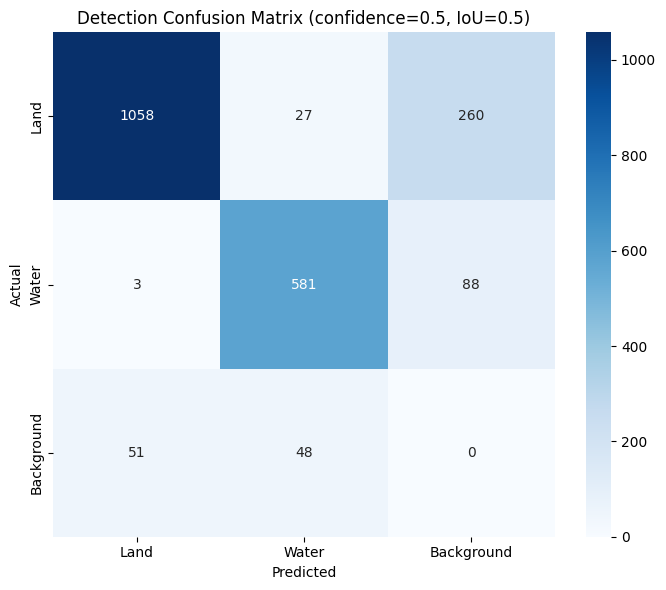


Detection metrics:
mAP@0.50: 0.8534 (85.34%)
mAR@0.5: 0.8695 (86.95%)
mAP@0.75: 0.7986 (79.86%)
mAR@0.75: 0.8222 (82.22%)
mAP@0.50:0.95: 0.6902 (69.02%)
mAR@0.50:0.95: 0.7348 (73.48%)


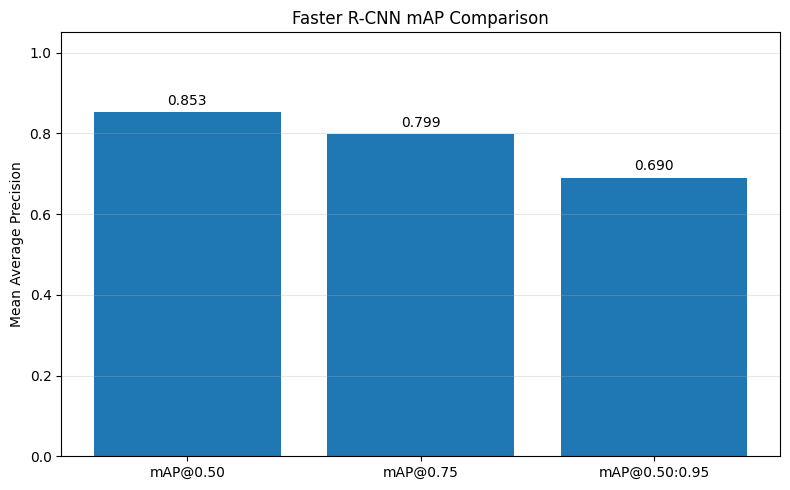


Class-wise AP:
Class  mAP@0.50  mAP@0.75  mAP@0.50:0.95
 Land    0.8156    0.7754         0.7008
Water    0.8912    0.8218         0.6796


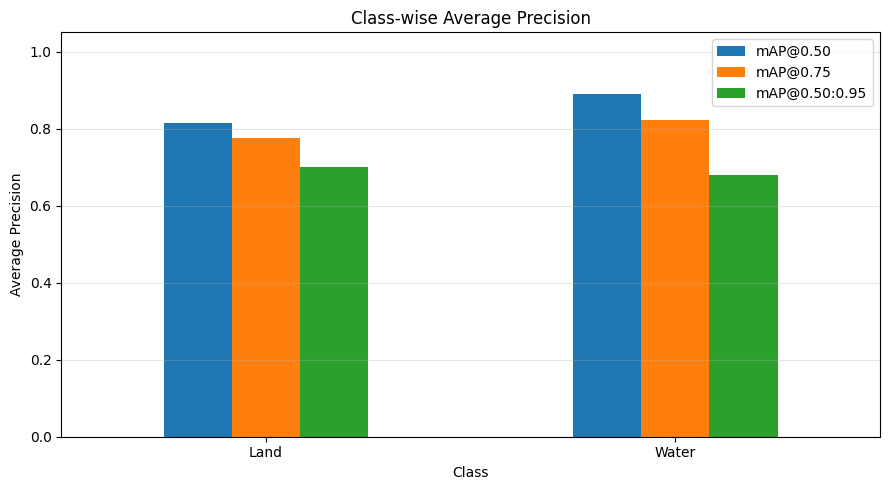

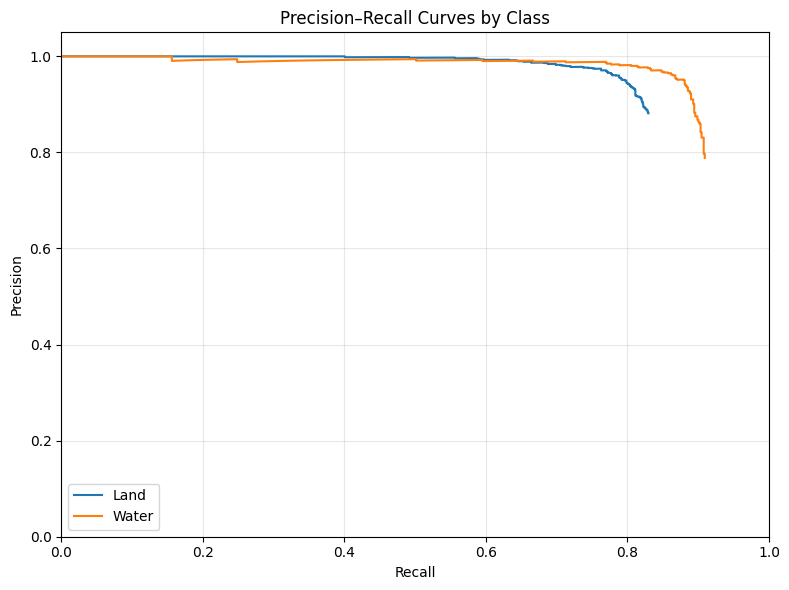

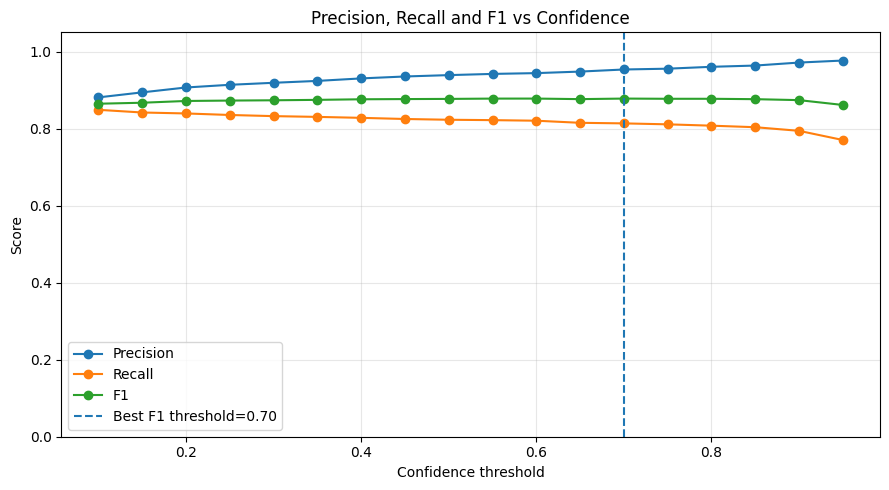


Class-wise metrics at confidence 0.50:
class  precision  recall     F1   TP  FP  FN
 Land     0.9550  0.7896 0.8645 1062  50 283
Water     0.9116  0.8899 0.9006  598  58  74


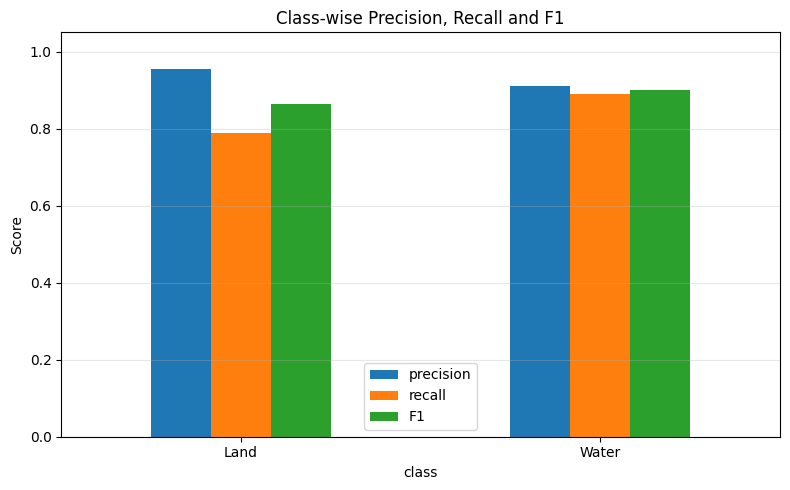

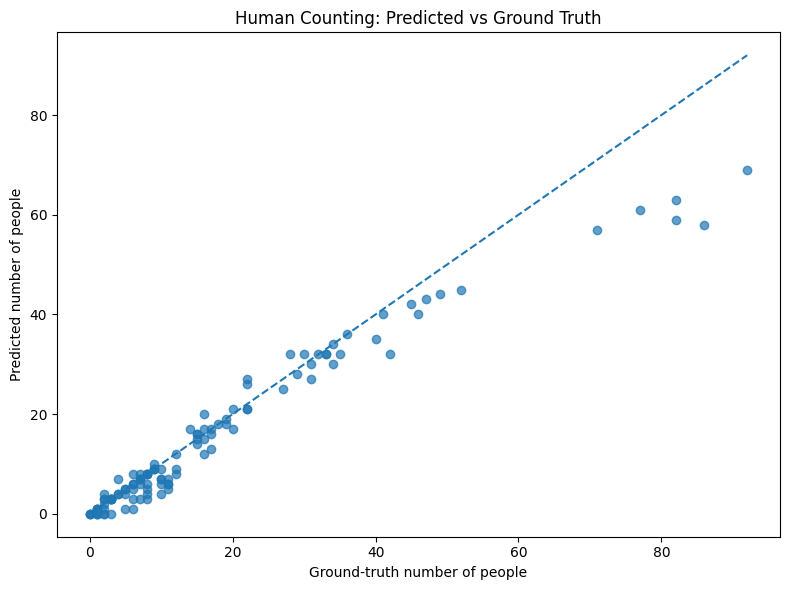

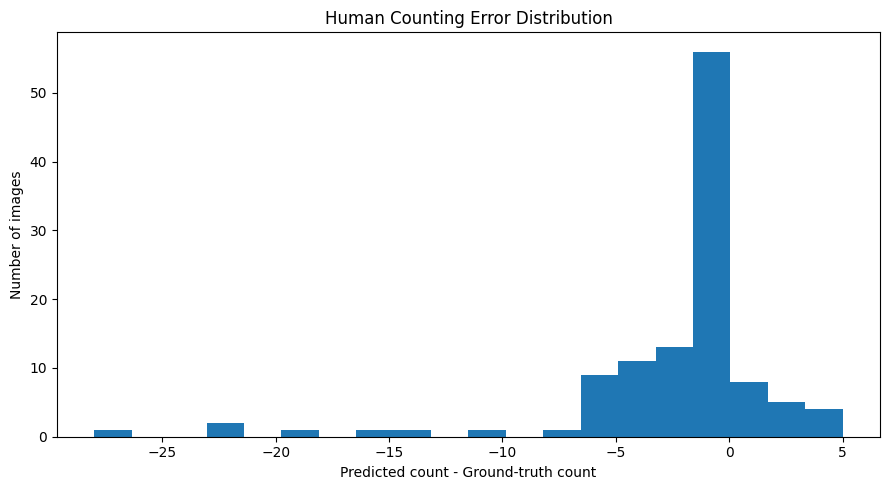


Inference speed: {'timed_images': 114, 'total_inference_seconds': 23.03938499999913, 'milliseconds_per_image': 202.099868421045, 'images_per_second': 4.9480487434887825}

Human counting MAE: 2.8333
Human counting RMSE: 5.5131

All remaining outputs saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs

Files generated:
 - class_wise_AP.csv
 - class_wise_AP.png
 - class_wise_precision_recall_f1.csv
 - class_wise_precision_recall_f1.png
 - confidence_threshold_curve.png
 - confidence_threshold_metrics.csv
 - confusion_matrix.csv
 - confusion_matrix.png
 - evaluation_results.json
 - final_evaluation_metrics.png
 - human_count_error_distribution.png
 - human_count_scatter.png
 - loss_components.png
 - loss_curve.png
 - map_evaluation_results.json
 - map_threshold_comparison.png
 - per_image_human_counts.csv
 - precision_recall_by_class.png
 - prediction_001.png
 - prediction_002.png
 - prediction_003.png
 - prediction_004.png
 - prediction_005.png
 - prediction_006.png
 - prediction

In [44]:

# Remaining Faster R-CNN evaluation outputs
# Uses existing predictions; does NOT retrain the model.

!pip install -q torchmetrics pycocotools

import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torchvision.ops import box_iou
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from sklearn.metrics import mean_absolute_error, mean_squared_error

OUT = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
os.makedirs(OUT, exist_ok=True)

CLASS_NAMES = {1: "Land", 2: "Water"}
CONF = 0.50
IOU = 0.50

# Prepare predictions and targets on CPU
preds, targets = [], []

for p, t in zip(all_preds, all_targets):
    preds.append({
        "boxes": p["boxes"].detach().cpu().float(),
        "scores": p["scores"].detach().cpu().float(),
        "labels": p["labels"].detach().cpu().long()
    })
    targets.append({
        "boxes": t["boxes"].detach().cpu().float(),
        "labels": t["labels"].detach().cpu().long()
    })

assert len(preds) == len(targets) and len(preds) > 0

# =====================================================
# 1. CONFUSION MATRIX: Land, Water, Background
# =====================================================
cm = np.zeros((3, 3), dtype=int)

for p, t in zip(preds, targets):
    keep = p["scores"] >= CONF
    pb, pl = p["boxes"][keep], p["labels"][keep]
    gb, gl = t["boxes"], t["labels"]

    matched_p, matched_g = set(), set()

    if len(pb) and len(gb):
        overlaps = box_iou(gb, pb)
        pairs = [
            (float(overlaps[g, j]), g, j)
            for g in range(len(gb))
            for j in range(len(pb))
            if overlaps[g, j] >= IOU
        ]
        pairs.sort(reverse=True)

        for overlap, g, j in pairs:
            if g in matched_g or j in matched_p:
                continue
            actual, predicted = int(gl[g]), int(pl[j])
            if actual in (1, 2) and predicted in (1, 2):
                cm[actual-1, predicted-1] += 1
            matched_g.add(g)
            matched_p.add(j)

    for g in range(len(gb)):
        if g not in matched_g and int(gl[g]) in (1, 2):
            cm[int(gl[g])-1, 2] += 1

    for j in range(len(pb)):
        if j not in matched_p and int(pl[j]) in (1, 2):
            cm[2, int(pl[j])-1] += 1

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Land", "Water", "Background"],
    yticklabels=["Land", "Water", "Background"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Detection Confusion Matrix (confidence={CONF}, IoU={IOU})")
plt.tight_layout()
plt.savefig(f"{OUT}/confusion_matrix.png", dpi=300)
plt.show()
np.savetxt(f"{OUT}/confusion_matrix.csv", cm, delimiter=",", fmt="%d")

# =====================================================
# 2. mAP@0.50, mAP@0.75, mAP@0.50:0.95 AND CLASS AP
# =====================================================
metric_specs = {
    "mAP@0.50": [0.50],
    "mAP@0.75": [0.75],
    "mAP@0.50:0.95": list(np.arange(0.50, 0.96, 0.05))
}

map_results = {}
per_class_results = {}

for metric_name, iou_thresholds in metric_specs.items():
    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        iou_thresholds=iou_thresholds,
        class_metrics=True
    )
    metric.update(preds, targets)
    result = metric.compute()

    map_results[metric_name] = float(result["map"])
    if "mar_100" in result:
        map_results["mAR@0.50:0.95" if len(iou_thresholds) > 1
                     else "mAR@" + str(iou_thresholds[0])] = float(result["mar_100"])

    classes = result.get("classes", torch.tensor([])).tolist()
    class_maps = result.get("map_per_class", torch.tensor([])).tolist()

    for cls, ap in zip(classes, class_maps):
        cls = int(cls)
        per_class_results.setdefault(str(cls), {})[metric_name] = float(ap)

print("\nDetection metrics:")
for name, value in map_results.items():
    print(f"{name}: {value:.4f} ({value*100:.2f}%)")

# mAP graph
main_map_keys = ["mAP@0.50", "mAP@0.75", "mAP@0.50:0.95"]
map_values = [map_results[k] for k in main_map_keys]

plt.figure(figsize=(8, 5))
bars = plt.bar(main_map_keys, map_values)
plt.ylim(0, 1.05)
plt.ylabel("Mean Average Precision")
plt.title("Faster R-CNN mAP Comparison")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/map_threshold_comparison.png", dpi=300)
plt.show()

# Class-wise AP graph
class_rows = []
for cls, vals in per_class_results.items():
    row = {"Class": CLASS_NAMES.get(int(cls), f"Class {cls}")}
    row.update(vals)
    class_rows.append(row)

if class_rows:
    class_df = pd.DataFrame(class_rows)
    print("\nClass-wise AP:")
    print(class_df.round(4).to_string(index=False))
    class_df.to_csv(f"{OUT}/class_wise_AP.csv", index=False)

    cols = [c for c in main_map_keys if c in class_df.columns]
    if cols:
        ax = class_df.set_index("Class")[cols].plot(
            kind="bar", figsize=(9, 5), ylim=(0, 1.05)
        )
        ax.set_ylabel("Average Precision")
        ax.set_title("Class-wise Average Precision")
        plt.xticks(rotation=0)
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.savefig(f"{OUT}/class_wise_AP.png", dpi=300)
        plt.show()

# =====================================================
# 3. PRECISION-RECALL CURVES FOR EACH CLASS
# =====================================================
def get_pr_curve(class_id):
    detections = []
    total_gt = 0

    for image_idx, (p, t) in enumerate(zip(preds, targets)):
        gt_boxes = t["boxes"][t["labels"] == class_id]
        total_gt += len(gt_boxes)

        mask = (p["labels"] == class_id)
        for box, score in zip(p["boxes"][mask], p["scores"][mask]):
            detections.append((float(score), image_idx, box))

    detections.sort(key=lambda x: x[0], reverse=True)
    matched = {i: set() for i in range(len(targets))}
    tp, fp = [], []

    for score, image_idx, box in detections:
        gt_boxes = targets[image_idx]["boxes"][
            targets[image_idx]["labels"] == class_id
        ]

        if len(gt_boxes) == 0:
            tp.append(0)
            fp.append(1)
            continue

        overlaps = box_iou(box.unsqueeze(0), gt_boxes).squeeze(0)
        best_iou, best_idx = overlaps.max(dim=0)
        best_idx = int(best_idx)

        if best_iou >= IOU and best_idx not in matched[image_idx]:
            tp.append(1)
            fp.append(0)
            matched[image_idx].add(best_idx)
        else:
            tp.append(0)
            fp.append(1)

    if total_gt == 0:
        return np.array([]), np.array([])

    tp_cum, fp_cum = np.cumsum(tp), np.cumsum(fp)
    recall = tp_cum / total_gt
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1)
    return recall, precision

plt.figure(figsize=(8, 6))
for class_id, name in CLASS_NAMES.items():
    recall, precision = get_pr_curve(class_id)
    if len(recall):
        plt.plot(recall, precision, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves by Class")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/precision_recall_by_class.png", dpi=300)
plt.show()

# =====================================================
# 4. PRECISION, RECALL AND F1 VS CONFIDENCE THRESHOLD
# =====================================================
thresholds = np.arange(0.10, 0.96, 0.05)
threshold_rows = []

for threshold in thresholds:
    tp = fp = fn = 0

    for p, t in zip(preds, targets):
        mask = p["scores"] >= threshold
        pb, pl = p["boxes"][mask], p["labels"][mask]
        gb, gl = t["boxes"], t["labels"]
        matched_p, matched_g = set(), set()

        if len(pb) and len(gb):
            overlaps = box_iou(gb, pb)
            pairs = [
                (float(overlaps[g, j]), g, j)
                for g in range(len(gb))
                for j in range(len(pb))
                if overlaps[g, j] >= IOU
            ]
            pairs.sort(reverse=True)

            for overlap, g, j in pairs:
                if g in matched_g or j in matched_p:
                    continue
                if int(gl[g]) == int(pl[j]):
                    matched_g.add(g)
                    matched_p.add(j)

        tp += len(matched_g)
        fp += len(pb) - len(matched_p)
        fn += len(gb) - len(matched_g)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    threshold_rows.append({
        "confidence": round(float(threshold), 2),
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "TP": tp, "FP": fp, "FN": fn
    })

threshold_df = pd.DataFrame(threshold_rows)
threshold_df.to_csv(f"{OUT}/confidence_threshold_metrics.csv", index=False)
best_row = threshold_df.loc[threshold_df["F1"].idxmax()]

plt.figure(figsize=(9, 5))
for col in ["precision", "recall", "F1"]:
    plt.plot(threshold_df["confidence"], threshold_df[col],
             marker="o", label=col.capitalize())
plt.axvline(best_row["confidence"], linestyle="--",
            label=f"Best F1 threshold={best_row['confidence']:.2f}")
plt.xlabel("Confidence threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Confidence")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/confidence_threshold_curve.png", dpi=300)
plt.show()

# =====================================================
# 5. CLASS-WISE PRECISION, RECALL AND F1 AT CONF=0.50
# =====================================================
rows = []

for class_id, class_name in CLASS_NAMES.items():
    tp = fp = fn = 0

    for p, t in zip(preds, targets):
        mask = (p["scores"] >= CONF) & (p["labels"] == class_id)
        pb = p["boxes"][mask]
        gb = t["boxes"][t["labels"] == class_id]

        matched_p, matched_g = set(), set()
        if len(pb) and len(gb):
            overlaps = box_iou(gb, pb)
            pairs = [
                (float(overlaps[g, j]), g, j)
                for g in range(len(gb))
                for j in range(len(pb))
                if overlaps[g, j] >= IOU
            ]
            pairs.sort(reverse=True)
            for overlap, g, j in pairs:
                if g not in matched_g and j not in matched_p:
                    matched_g.add(g)
                    matched_p.add(j)

        tp += len(matched_g)
        fp += len(pb) - len(matched_p)
        fn += len(gb) - len(matched_g)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    rows.append({
        "class": class_name,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "TP": tp, "FP": fp, "FN": fn
    })

class_metrics_df = pd.DataFrame(rows)
class_metrics_df.to_csv(f"{OUT}/class_wise_precision_recall_f1.csv", index=False)
print("\nClass-wise metrics at confidence 0.50:")
print(class_metrics_df.round(4).to_string(index=False))

ax = class_metrics_df.set_index("class")[
    ["precision", "recall", "F1"]
].plot(kind="bar", figsize=(8, 5), ylim=(0, 1.05))
ax.set_title("Class-wise Precision, Recall and F1")
ax.set_ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/class_wise_precision_recall_f1.png", dpi=300)
plt.show()

# =====================================================
# 6. HUMAN COUNTING: MAE, RMSE AND PER-IMAGE CSV
# Counts detections with confidence >= 0.50
# =====================================================
true_counts = np.array([len(t["boxes"]) for t in targets])
pred_counts = np.array([
    int((p["scores"] >= CONF).sum()) for p in preds
])

mae = float(mean_absolute_error(true_counts, pred_counts))
rmse = float(np.sqrt(mean_squared_error(true_counts, pred_counts)))

count_df = pd.DataFrame({
    "image_index": np.arange(1, len(preds) + 1),
    "ground_truth_count": true_counts,
    "predicted_count": pred_counts,
    "count_error": pred_counts - true_counts,
    "absolute_error": np.abs(pred_counts - true_counts)
})
count_df.to_csv(f"{OUT}/per_image_human_counts.csv", index=False)

plt.figure(figsize=(8, 6))
plt.scatter(true_counts, pred_counts, alpha=0.7)
max_count = max(int(true_counts.max()), int(pred_counts.max()), 1)
plt.plot([0, max_count], [0, max_count], linestyle="--")
plt.xlabel("Ground-truth number of people")
plt.ylabel("Predicted number of people")
plt.title("Human Counting: Predicted vs Ground Truth")
plt.tight_layout()
plt.savefig(f"{OUT}/human_count_scatter.png", dpi=300)
plt.show()

plt.figure(figsize=(9, 5))
plt.hist(count_df["count_error"], bins=20)
plt.xlabel("Predicted count - Ground-truth count")
plt.ylabel("Number of images")
plt.title("Human Counting Error Distribution")
plt.tight_layout()
plt.savefig(f"{OUT}/human_count_error_distribution.png", dpi=300)
plt.show()

# =====================================================
# 7. INFERENCE SPEED (if model and test_loader exist)
# This runs inference only, not training.
# =====================================================
speed_results = {}

if "model" in globals() and "test_loader" in globals():
    device = next(model.parameters()).device
    model.eval()
    elapsed = 0.0
    image_count = 0

    with torch.inference_mode():
        for images, _ in test_loader:
            images = [im.to(device) for im in images]

            if device.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()

            _ = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()
            elapsed += time.perf_counter() - start
            image_count += len(images)

    speed_results = {
        "timed_images": image_count,
        "total_inference_seconds": elapsed,
        "milliseconds_per_image": 1000 * elapsed / max(image_count, 1),
        "images_per_second": image_count / max(elapsed, 1e-12)
    }
    print("\nInference speed:", speed_results)
else:
    print("\nInference speed skipped: model or test_loader is not available.")

# =====================================================
# 8. SAVE CONSOLIDATED RESULTS
# =====================================================
summary = {
    "number_of_test_images": len(preds),
    "confidence_threshold": CONF,
    "iou_threshold_for_detection_metrics": IOU,
    "mAP_and_mAR": map_results,
    "class_wise_AP": per_class_results,
    "class_wise_precision_recall_f1": rows,
    "best_F1_confidence_threshold": float(best_row["confidence"]),
    "best_F1": float(best_row["F1"]),
    "human_counting_MAE": mae,
    "human_counting_RMSE": rmse,
    "inference_speed": speed_results
}

with open(f"{OUT}/remaining_evaluation_results.json", "w") as f:
    json.dump(summary, f, indent=4)

print("\nHuman counting MAE:", round(mae, 4))
print("Human counting RMSE:", round(rmse, 4))
print("\nAll remaining outputs saved to:", OUT)
print("\nFiles generated:")
for filename in sorted(os.listdir(OUT)):
    if filename.endswith((".png", ".csv", ".json")):
        print(" -", filename)


In [45]:

import os
import torch
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from torchvision.transforms.functional import to_pil_image
from PIL import ImageDraw, ImageFont

# Output folder
output_dir = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
styled_dir = os.path.join(output_dir, "styled_predictions")
os.makedirs(styled_dir, exist_ok=True)

CONF_THRESHOLD = 0.50

# Use your existing trained model and test_loader
model.eval()
device = next(model.parameters()).device

try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 22)
    header_font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 24)
except:
    font = ImageFont.load_default()
    header_font = ImageFont.load_default()

image_number = 0

with torch.inference_mode():
    for images, targets in test_loader:
        images = [img.to(device) for img in images]
        predictions = model(images)

        for image_tensor, pred in zip(images, predictions):
            image_number += 1

            # Convert image to RGB PIL image
            img = to_pil_image(image_tensor.detach().cpu()).convert("RGB")
            draw = ImageDraw.Draw(img)

            boxes = pred["boxes"].detach().cpu()
            labels = pred["labels"].detach().cpu()
            scores = pred["scores"].detach().cpu()

            # Filter low-confidence detections
            keep = scores >= CONF_THRESHOLD
            boxes = boxes[keep]
            labels = labels[keep]
            scores = scores[keep]

            # Class mapping: 1 = Land, 2 = Water
            land_count = int((labels == 1).sum())
            water_count = int((labels == 2).sum())
            total_count = land_count + water_count

            # Draw clean green boxes and transparent text
            for box, label, score in zip(boxes, labels, scores):
                x1, y1, x2, y2 = [int(v) for v in box.tolist()]

                # Ignore invalid class IDs
                if int(label) not in (1, 2):
                    continue

                class_name = "Human on land" if int(label) == 1 else "Human in water"
                text = f"{class_name}: {float(score):.2f}"

                # Green bounding box
                draw.rectangle(
                    [x1, y1, x2, y2],
                    outline=(0, 255, 50),
                    width=3
                )

                # Text with no filled background
                # Add a subtle dark outline to preserve readability
                draw.text(
                    (x1, max(0, y1 - 25)),
                    text,
                    font=font,
                    fill=(0, 255, 50),
                    stroke_width=1,
                    stroke_fill=(0, 0, 0)
                )

            # Header counts at top of image
            header = (
                f"Land: {land_count}   |   "
                f"Water: {water_count}   |   "
                f"Total People: {total_count}"
            )

            # Draw a thin dark outline around green header text,
            # without adding a filled background
            draw.text(
                (12, 10),
                header,
                font=header_font,
                fill=(0, 255, 50),
                stroke_width=2,
                stroke_fill=(0, 0, 0)
            )

            save_path = os.path.join(
                styled_dir, f"prediction_{image_number:03d}.jpg"
            )
            img.save(save_path, quality=95)

print(f"Processed {image_number} test images.")
print(f"Styled predictions saved to: {styled_dir}")


Processed 114 test images.
Styled predictions saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/styled_predictions


In [48]:

# LARGE, HUMAN-READABLE TEXT SETTINGS

# Use much larger fonts
label_font = load_font(32, bold=True)      # Text above bounding boxes
summary_font = load_font(40, bold=True)    # Summary at top of image

# Larger spacing for the three-line summary
summary_lines = [
    f"PEOPLE ON LAND: {land_count}",
    f"PEOPLE IN WATER: {water_count}",
    f"TOTAL PEOPLE: {total_count}"
]

y = 15
for line in summary_lines:
    draw.text(
        (18, y),
        line,
        font=summary_font,
        fill=(0, 255, 40),
        stroke_width=3,
        stroke_fill=(0, 0, 0)
    )
    y += 52

# LARGE TEXT ABOVE EACH BOUNDING BOX — NO BACKGROUND
for box, label, score in zip(boxes, labels, scores):
    x1, y1, x2, y2 = [int(v) for v in box.tolist()]

    draw.rectangle(
        (x1, y1, x2, y2),
        outline=(0, 255, 40),
        width=4
    )

    class_name = (
        "Human on land" if int(label) == 1
        else "Human in water"
    )
    label_text = f"{class_name}: {float(score):.2f}"

    # Place above the box, or just inside if near the top edge
    text_y = y1 - 42
    if text_y < 0:
        text_y = y1 + 4

    draw.text(
        (x1, text_y),
        label_text,
        font=label_font,
        fill=(0, 255, 40),
        stroke_width=3,
        stroke_fill=(0, 0, 0)
    )


In [49]:

import os
import torch
from PIL import ImageDraw, ImageFont
from torchvision.transforms.functional import to_pil_image

# Output directory
output_dir = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
styled_dir = os.path.join(output_dir, "final_styled_predictions")
os.makedirs(styled_dir, exist_ok=True)

CONF_THRESHOLD = 0.50

GREEN = (0, 255, 30)
WHITE = (255, 255, 255)
BLACK = (0, 0, 0)

def get_font(size, bold=True):
    path = (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"
        if bold else
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
    )
    try:
        return ImageFont.truetype(path, size)
    except OSError:
        return ImageFont.load_default()

# Large readable text
label_font = get_font(27)
count_font = get_font(30)

model.eval()
device = next(model.parameters()).device
image_number = 0

with torch.inference_mode():
    for images, _ in test_loader:
        images_device = [im.to(device) for im in images]
        predictions = model(images_device)

        for image_tensor, prediction in zip(images, predictions):
            image_number += 1

            image = to_pil_image(image_tensor.detach().cpu()).convert("RGB")
            draw = ImageDraw.Draw(image)
            width, height = image.size

            boxes = prediction["boxes"].detach().cpu()
            labels = prediction["labels"].detach().cpu()
            scores = prediction["scores"].detach().cpu()

            # Keep confident predictions from the two human classes
            keep = (
                (scores >= CONF_THRESHOLD) &
                ((labels == 1) | (labels == 2))
            )
            boxes = boxes[keep]
            labels = labels[keep]
            scores = scores[keep]

            land_count = int((labels == 1).sum().item())
            water_count = int((labels == 2).sum().item())
            total_count = len(labels)

            # Count panel at top of image
            panel_lines = [
                f"TOTAL PEOPLE: {total_count}",
                f"ON LAND: {land_count}   |   IN WATER: {water_count}"
            ]

            padding = 14
            line_gap = 9
            line_heights = [
                draw.textbbox((0, 0), line, font=count_font)[3]
                for line in panel_lines
            ]
            panel_height = sum(line_heights) + line_gap + 2 * padding

            # Dark panel ONLY for the count summary
            draw.rectangle(
                (0, 0, width, panel_height),
                fill=(15, 25, 15)
            )

            y = padding
            for line, line_height in zip(panel_lines, line_heights):
                draw.text(
                    (padding, y),
                    line,
                    font=count_font,
                    fill=WHITE,
                    stroke_width=1,
                    stroke_fill=BLACK
                )
                y += line_height + line_gap

            # Draw bounding boxes and labels
            for box, label, score in zip(boxes, labels, scores):
                x1, y1, x2, y2 = [
                    int(v) for v in box.tolist()
                ]

                x1 = max(0, min(x1, width - 1))
                x2 = max(0, min(x2, width - 1))
                y1 = max(0, min(y1, height - 1))
                y2 = max(0, min(y2, height - 1))

                if x2 <= x1 or y2 <= y1:
                    continue

                # Bright green bounding box
                draw.rectangle(
                    (x1, y1, x2, y2),
                    outline=GREEN,
                    width=4
                )

                if int(label) == 1:
                    class_name = "Human on land"
                else:
                    class_name = "Human in water"

                label_text = f"{class_name}: {float(score):.2f}"

                # Place text above the box; move inside if needed
                text_y = y1 - 36
                if text_y < panel_height:
                    text_y = min(y1 + 3, height - 35)

                # Green text, no filled background
                draw.text(
                    (x1, text_y),
                    label_text,
                    font=label_font,
                    fill=GREEN,
                    stroke_width=2,
                    stroke_fill=BLACK
                )

            save_path = os.path.join(
                styled_dir,
                f"prediction_{image_number:03d}.jpg"
            )
            image.save(save_path, quality=95)

print(f"Generated {image_number} styled test images.")
print("Saved to:", styled_dir)


Generated 114 styled test images.
Saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/final_styled_predictions


In [50]:

import os
import torch
from PIL import ImageDraw, ImageFont
from torchvision.transforms.functional import to_pil_image

# =====================================================
# CONFIGURATION
# =====================================================
output_dir = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
save_dir = os.path.join(output_dir, "final_styled_predictions")
os.makedirs(save_dir, exist_ok=True)

CONF_THRESHOLD = 0.50

# Reference image styling
GREEN = (0, 255, 0)       # Neon green
BLACK = (0, 0, 0)
WHITE = (255, 255, 255)

# =====================================================
# FONT LOADING
# =====================================================
def get_font(size):
    font_path = "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"
    try:
        return ImageFont.truetype(font_path, size)
    except OSError:
        return ImageFont.load_default()

# Large, readable text
label_font = get_font(32)
count_font = get_font(30)

# =====================================================
# CHECK EXISTING VARIABLES
# =====================================================
if "model" not in globals():
    raise RuntimeError("Trained model variable 'model' is missing. Load your checkpoint first.")

if "test_loader" not in globals():
    raise RuntimeError("Variable 'test_loader' is missing. Recreate your test DataLoader first.")

model.eval()
device = next(model.parameters()).device

image_number = 0

# =====================================================
# RUN INFERENCE AND SAVE ALL TEST IMAGES
# =====================================================
with torch.inference_mode():
    for images, _ in test_loader:

        images_device = [image.to(device) for image in images]
        predictions = model(images_device)

        for image_tensor, prediction in zip(images, predictions):
            image_number += 1

            # Convert original test image to RGB
            image = to_pil_image(image_tensor.detach().cpu()).convert("RGB")
            draw = ImageDraw.Draw(image)
            width, height = image.size

            boxes = prediction["boxes"].detach().cpu()
            labels = prediction["labels"].detach().cpu()
            scores = prediction["scores"].detach().cpu()

            # Filter predictions by confidence and class
            keep = (
                (scores >= CONF_THRESHOLD) &
                ((labels == 1) | (labels == 2))
            )

            boxes = boxes[keep]
            labels = labels[keep]
            scores = scores[keep]

            # Class mapping: 1 = Land, 2 = Water
            land_count = int((labels == 1).sum().item())
            water_count = int((labels == 2).sum().item())
            total_count = len(labels)

            # -----------------------------------------
            # TOP SUMMARY PANEL
            # -----------------------------------------
            summary_lines = [
                f"TOTAL PEOPLE: {total_count}",
                f"PEOPLE ON LAND: {land_count}",
                f"PEOPLE IN WATER: {water_count}"
            ]

            padding = 12
            gap = 6

            line_heights = [
                draw.textbbox((0, 0), text, font=count_font)[3]
                for text in summary_lines
            ]

            panel_height = (
                sum(line_heights) + gap * (len(summary_lines) - 1)
                + 2 * padding
            )

            # Background applies only to the summary panel
            draw.rectangle(
                (0, 0, width, panel_height),
                fill=(0, 0, 0)
            )

            y = padding

            for text, line_height in zip(summary_lines, line_heights):
                draw.text(
                    (padding, y),
                    text,
                    font=count_font,
                    fill=WHITE
                )
                y += line_height + gap

            # -----------------------------------------
            # DRAW DETECTIONS
            # -----------------------------------------
            for box, label, score in zip(boxes, labels, scores):

                x1, y1, x2, y2 = [int(v) for v in box.tolist()]

                # Keep coordinates inside the image
                x1 = max(0, min(x1, width - 1))
                x2 = max(0, min(x2, width - 1))
                y1 = max(0, min(y1, height - 1))
                y2 = max(0, min(y2, height - 1))

                if x2 <= x1 or y2 <= y1:
                    continue

                # Bright green bounding box
                draw.rectangle(
                    (x1, y1, x2, y2),
                    outline=GREEN,
                    width=4
                )

                # Class label
                if int(label) == 1:
                    class_name = "Human on land"
                else:
                    class_name = "Human in water"

                label_text = f"{class_name}: {float(score):.2f}"

                # Put label above the box.
                # If there is insufficient room, place it inside.
                text_y = y1 - 40

                if text_y < panel_height:
                    text_y = min(y1 + 4, max(0, height - 40))

                # No filled background; green text with thin dark outline
                draw.text(
                    (x1, text_y),
                    label_text,
                    font=label_font,
                    fill=GREEN,
                    stroke_width=1,
                    stroke_fill=BLACK
                )

            # -----------------------------------------
            # SAVE TO GOOGLE DRIVE
            # -----------------------------------------
            filename = f"prediction_{image_number:03d}.jpg"
            save_path = os.path.join(save_dir, filename)

            image.save(save_path, quality=95)

print("\nAll test images processed.")
print("Number of images:", image_number)
print("Saved to:", save_dir)
print("Confidence threshold:", CONF_THRESHOLD)

print("\nSaved files:")
for filename in sorted(os.listdir(save_dir)):
    print(filename)



All test images processed.
Number of images: 114
Saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/final_styled_predictions
Confidence threshold: 0.5

Saved files:
prediction_001.jpg
prediction_002.jpg
prediction_003.jpg
prediction_004.jpg
prediction_005.jpg
prediction_006.jpg
prediction_007.jpg
prediction_008.jpg
prediction_009.jpg
prediction_010.jpg
prediction_011.jpg
prediction_012.jpg
prediction_013.jpg
prediction_014.jpg
prediction_015.jpg
prediction_016.jpg
prediction_017.jpg
prediction_018.jpg
prediction_019.jpg
prediction_020.jpg
prediction_021.jpg
prediction_022.jpg
prediction_023.jpg
prediction_024.jpg
prediction_025.jpg
prediction_026.jpg
prediction_027.jpg
prediction_028.jpg
prediction_029.jpg
prediction_030.jpg
prediction_031.jpg
prediction_032.jpg
prediction_033.jpg
prediction_034.jpg
prediction_035.jpg
prediction_036.jpg
prediction_037.jpg
prediction_038.jpg
prediction_039.jpg
prediction_040.jpg
prediction_041.jpg
prediction_042.jpg
prediction_043.jpg
predicti

In [54]:

import os
from PIL import ImageFont

def load_bold_font(size):
    font_paths = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
        "/usr/local/share/fonts/DejaVuSans-Bold.ttf"
    ]

    for path in font_paths:
        if os.path.exists(path):
            return ImageFont.truetype(path, size)

    # Portable fallback if none of the font files exist
    try:
        import matplotlib.font_manager as fm
        return ImageFont.truetype(
            fm.findfont(fm.FontProperties(weight="bold")),
            size
        )
    except Exception:
        return ImageFont.load_default()

# Large, bold text matching your reference style
label_font = load_bold_font(52)
count_font = load_bold_font(32)

print("Fonts loaded successfully.")


Fonts loaded successfully.


In [57]:

!apt-get update -qq
!apt-get install -y -qq fonts-dejavu-core

import os
from PIL import ImageFont

font_candidates = [
    "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSansCondensed-Bold.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans-BoldOblique.ttf"
]

font_path = next(
    (p for p in font_candidates if os.path.isfile(p)),
    None
)

if font_path is None:
    raise FileNotFoundError("DejaVu bold font was not installed.")

label_font = ImageFont.truetype(font_path, 52)
count_font = ImageFont.truetype(font_path, 32)

print("Font loaded:", font_path)


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-dejavu-mono.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../fonts-dejavu-mono_2.37-8_all.deb ...
Unpacking fonts-dejavu-mono (2.37-8) ...
Selecting previously unselected package fonts-dejavu-core.
Preparing to unpack .../fonts-dejavu-core_2.37-8_all.deb ...
Unpacking fonts-dejavu-core (2.37-8) ...
Setting up fonts-dejavu-mono (2.37-8) ...
Setting up fonts-dejavu-core (2.37-8) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
Font loaded: /usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf


In [58]:
label_font = ImageFont.truetype(font_path, 52)
count_font = ImageFont.truetype(font_path, 32)

Model loaded successfully.
Device: cuda
Output folder: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/predictions_neon_green


Generating predictions:   0%|          | 0/57 [00:00<?, ?it/s]


Completed: 114 images processed.
Predictions saved to:
/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/predictions_neon_green
prediction_001.png


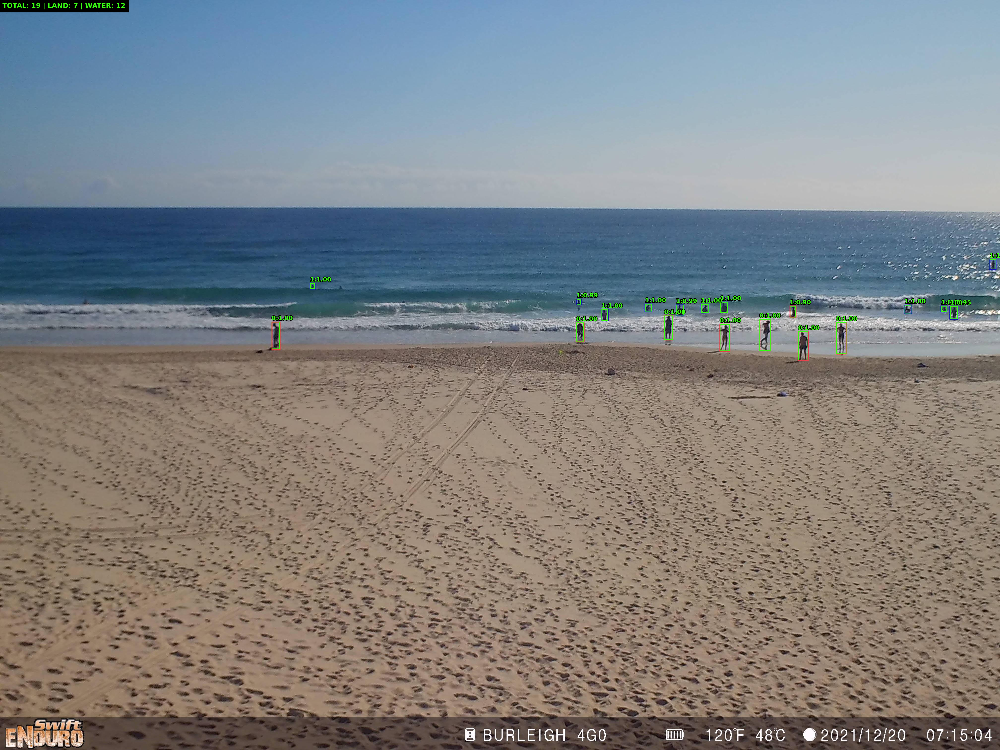

prediction_002.png


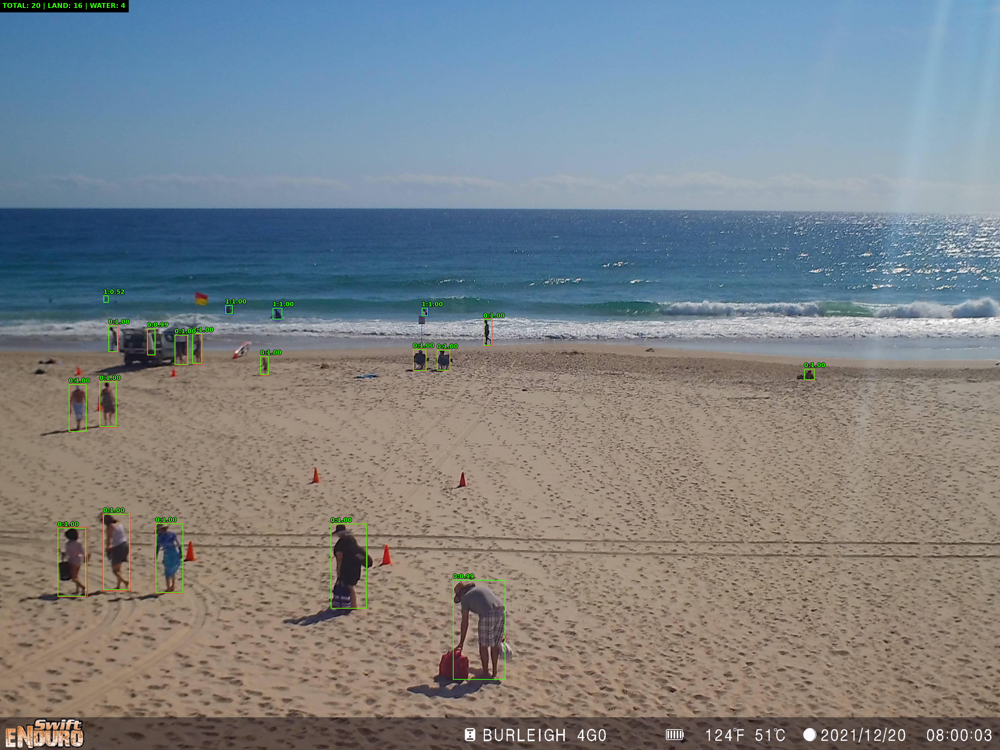

prediction_003.png


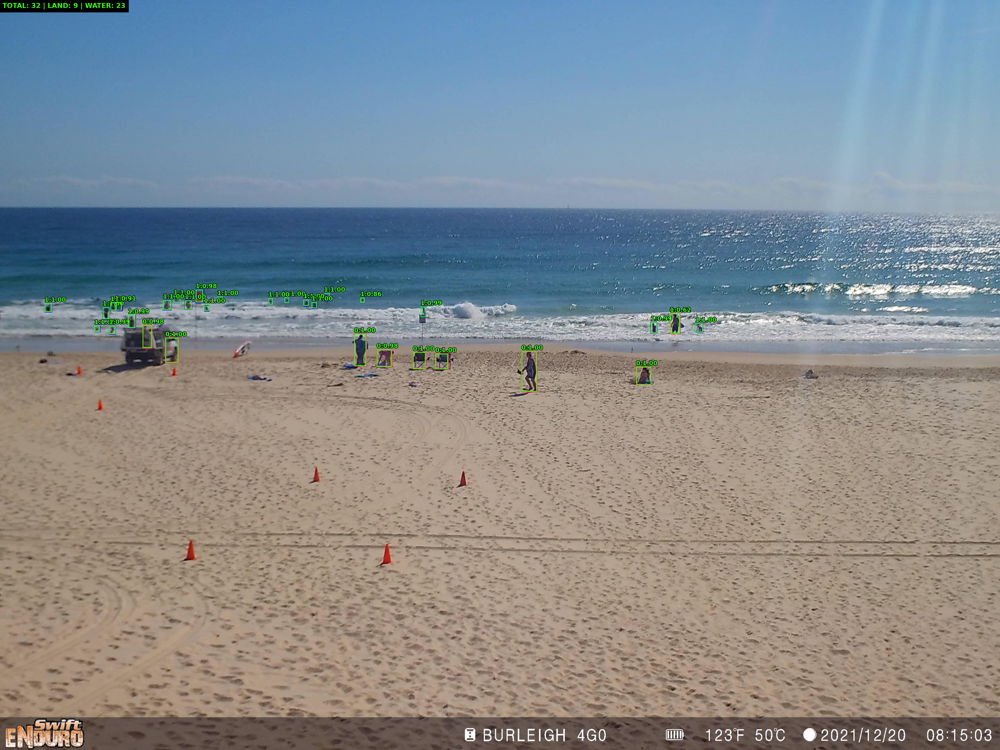

prediction_004.png


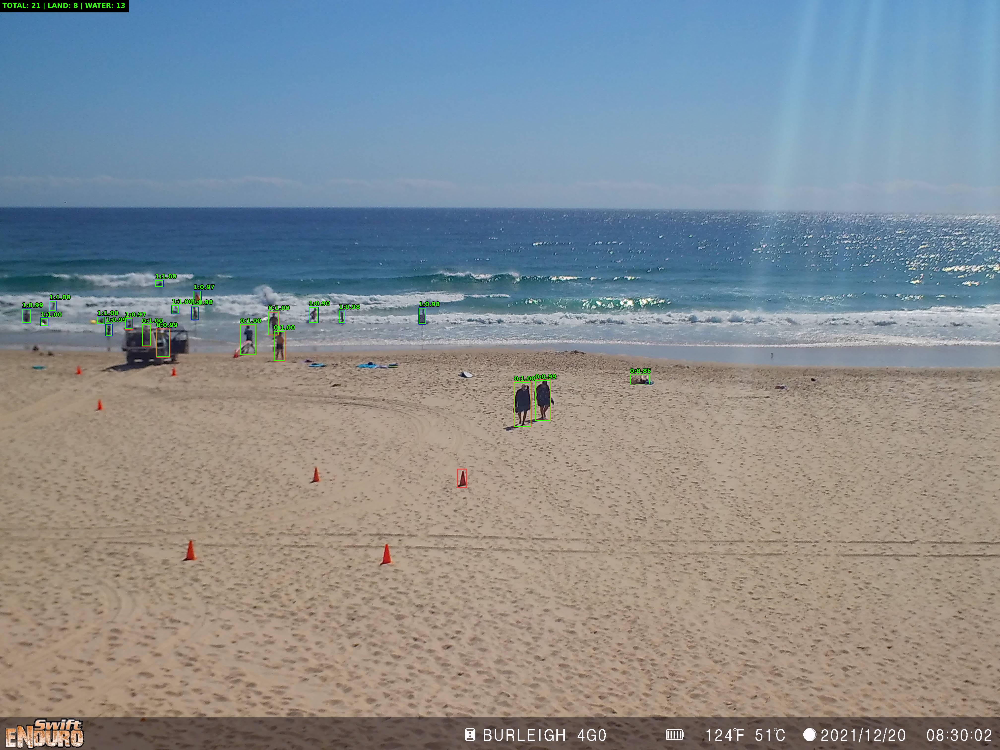

prediction_005.png


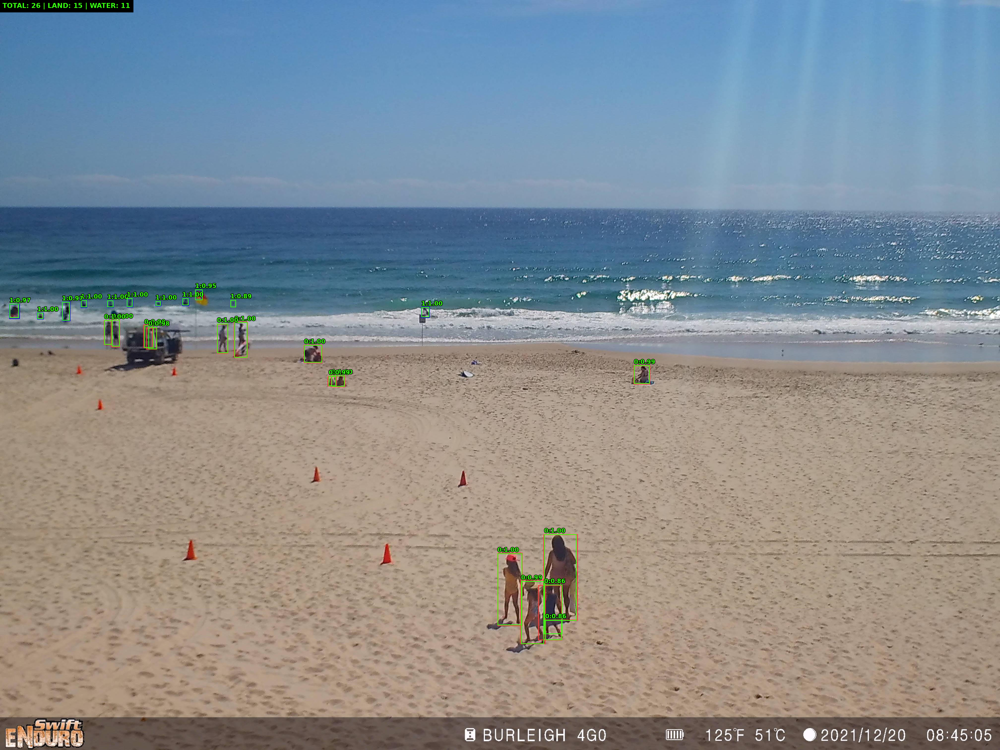


Count summary saved to: /content/drive/MyDrive/FasterRCNN_50Epoch_Outputs/predictions_neon_green/prediction_counts.csv


In [59]:
import os
import torch
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from PIL import Image, ImageDraw, ImageFont
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.transforms import functional as F
from tqdm.auto import tqdm

# ==========================================
# 1. CONFIGURATION
# ==========================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

output_dir = "/content/drive/MyDrive/FasterRCNN_50Epoch_Outputs"
save_dir = os.path.join(output_dir, "predictions_neon_green")
os.makedirs(save_dir, exist_ok=True)

confidence_threshold = 0.50

# Font sizes in pixels
label_font_size = 24
summary_font_size = 27

# Neon green
NEON_GREEN = (57, 255, 20)
BOX_WIDTH = 3

# ==========================================
# 2. LOAD FONT
# ==========================================

font_path = "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"

if not os.path.exists(font_path):
    !apt-get -qq update
    !apt-get -qq install -y fonts-dejavu-core

label_font = ImageFont.truetype(font_path, label_font_size)
summary_font = ImageFont.truetype(font_path, summary_font_size)

# ==========================================
# 3. LOAD TRAINED MODEL
# ==========================================

checkpoint_path = (
    "/content/drive/MyDrive/fasterrcnn_resume_rebuilt.pth"
)

model = fasterrcnn_resnet50_fpn_v2(
    weights=None,
    weights_backbone=None,
    num_classes=3
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Model loaded successfully.")
print("Device:", device)
print("Output folder:", save_dir)

# ==========================================
# 4. DRAW PREDICTIONS
# ==========================================

def draw_predictions(image, prediction):
    image = image.convert("RGB")
    draw = ImageDraw.Draw(image)

    boxes = prediction["boxes"].detach().cpu()
    labels = prediction["labels"].detach().cpu()
    scores = prediction["scores"].detach().cpu()

    land_count = 0
    water_count = 0

    # Keep detections above the confidence threshold
    valid_indices = [
        i for i, score in enumerate(scores)
        if score.item() >= confidence_threshold
    ]

    for i in valid_indices:
        box = boxes[i].tolist()
        model_label = int(labels[i].item())
        score = float(scores[i].item())

        # Model labels: 1 and 2
        # Display labels: 0 and 1
        class_id = model_label - 1

        if class_id == 0:
            land_count += 1
        elif class_id == 1:
            water_count += 1

        x1, y1, x2, y2 = map(int, box)

        # Draw bounding box
        draw.rectangle(
            [(x1, y1), (x2, y2)],
            outline=NEON_GREEN,
            width=BOX_WIDTH
        )

        # Class ID and confidence, without a filled label background
        label_text = f"{class_id}:{score:.2f}"

        text_x = max(0, x1)
        text_y = max(0, y1 - label_font_size - 5)

        # Black outline improves readability without a background panel
        draw.text(
            (text_x, text_y),
            label_text,
            font=label_font,
            fill=NEON_GREEN,
            stroke_width=2,
            stroke_fill=(0, 0, 0)
        )

    # ==========================================
    # 5. TOP SUMMARY PANEL
    # ==========================================

    total_count = land_count + water_count

    summary_text = (
        f"TOTAL: {total_count} | "
        f"LAND: {land_count} | "
        f"WATER: {water_count}"
    )

    bbox = draw.textbbox(
        (0, 0),
        summary_text,
        font=summary_font,
        stroke_width=1
    )

    text_width = bbox[2] - bbox[0]
    text_height = bbox[3] - bbox[1]

    padding = 10
    panel_height = text_height + 2 * padding
    panel_width = text_width + 2 * padding

    # Black summary panel at the top
    draw.rectangle(
        [(0, 0), (panel_width, panel_height)],
        fill=(0, 0, 0)
    )

    draw.text(
        (padding, padding - bbox[1]),
        summary_text,
        font=summary_font,
        fill=NEON_GREEN
    )

    return image, total_count, land_count, water_count

# ==========================================
# 6. GET TEST IMAGES
# ==========================================

# Uses the existing test_loader from your notebook.
# Each batch should contain (images, targets).

if "test_loader" not in globals():
    raise NameError(
        "test_loader was not found. Run your dataset and test-loader "
        "setup cells before running this cell."
    )

# ==========================================
# 7. GENERATE AND SAVE PREDICTIONS
# ==========================================

image_counter = 0
summary_rows = []

with torch.no_grad():
    for batch_idx, batch in enumerate(tqdm(test_loader, desc="Generating predictions")):
        images = batch[0]

        images = [img.to(device) for img in images]
        predictions = model(images)

        for image_tensor, prediction in zip(images, predictions):
            image_counter += 1

            # Convert tensor to PIL image
            original_image = F.to_pil_image(
                image_tensor.detach().cpu()
            )

            # Draw boxes, labels, and summary
            result_image, total, land, water = draw_predictions(
                original_image,
                prediction
            )

            # Save in the new output folder
            filename = f"prediction_{image_counter:03d}.png"
            save_path = os.path.join(save_dir, filename)

            result_image.save(save_path)

            summary_rows.append({
                "image": filename,
                "total_people": total,
                "land_people": land,
                "water_people": water
            })

print(f"\nCompleted: {image_counter} images processed.")
print(f"Predictions saved to:\n{save_dir}")

# ==========================================
# 8. DISPLAY SAMPLE PREDICTIONS
# ==========================================

from IPython.display import display

sample_count = min(5, image_counter)

for i in range(1, sample_count + 1):
    image_path = os.path.join(
        save_dir,
        f"prediction_{i:03d}.png"
    )

    if os.path.exists(image_path):
        print(os.path.basename(image_path))
        display(Image.open(image_path))

# ==========================================
# 9. SAVE COUNT SUMMARY CSV
# ==========================================

import pandas as pd

summary_csv = os.path.join(
    save_dir,
    "prediction_counts.csv"
)

pd.DataFrame(summary_rows).to_csv(
    summary_csv,
    index=False
)

print("\nCount summary saved to:", summary_csv)

In [64]:
import os
import torch
from PIL import Image, ImageDraw, ImageFont
from torchvision.transforms.functional import to_pil_image
from tqdm.auto import tqdm

# =========================================
# OUTPUT FOLDER
# =========================================

save_dir = "/content/drive/MyDrive/Predicted_Images_Text_100"
os.makedirs(save_dir, exist_ok=True)

# =========================================
# TEXT AND BOX SETTINGS
# =========================================

font_path = "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"

# Bounding-box label text: 100 px
label_font = ImageFont.truetype(font_path, 100)

# Top summary text remains 52 px
count_font = ImageFont.truetype(font_path, 52)

GREEN = (57, 255, 20)
BLACK = (0, 0, 0)

CONF_THRESHOLD = 0.50
BOX_WIDTH = 5

# =========================================
# GENERATE AND SAVE ALL PREDICTIONS
# =========================================

model.eval()
device = next(model.parameters()).device
image_number = 0

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Saving predicted images"):

        batch_images = batch[0]
        predictions = model([img.to(device) for img in batch_images])

        for image_tensor, prediction in zip(batch_images, predictions):
            image_number += 1

            image = to_pil_image(
                image_tensor.detach().cpu()
            ).convert("RGB")

            draw = ImageDraw.Draw(image)

            boxes = prediction["boxes"].detach().cpu()
            labels = prediction["labels"].detach().cpu()
            scores = prediction["scores"].detach().cpu()

            land_count = 0
            water_count = 0

            for box, label, score in zip(boxes, labels, scores):
                if score.item() < CONF_THRESHOLD:
                    continue

                class_id = int(label.item()) - 1

                if class_id not in [0, 1]:
                    continue

                if class_id == 0:
                    land_count += 1
                else:
                    water_count += 1

                x1, y1, x2, y2 = map(int, box.tolist())

                # Neon-green bounding box
                draw.rectangle(
                    [(x1, y1), (x2, y2)],
                    outline=GREEN,
                    width=BOX_WIDTH
                )

                # Large class label with confidence
                label_text = f"{class_id}: {score.item():.2f}"

                text_bbox = draw.textbbox(
                    (0, 0),
                    label_text,
                    font=label_font,
                    stroke_width=3
                )

                text_height = text_bbox[3] - text_bbox[1]

                text_x = max(0, x1)
                text_y = y1 - text_height - 10

                if text_y < 0:
                    text_y = min(
                        y1 + 5,
                        max(0, image.height - text_height - 5)
                    )

                draw.text(
                    (text_x, text_y),
                    label_text,
                    font=label_font,
                    fill=GREEN,
                    stroke_width=3,
                    stroke_fill=BLACK
                )

            # Top summary panel
            summary = (
                f"TOTAL: {land_count + water_count} | "
                f"LAND: {land_count} | WATER: {water_count}"
            )

            summary_bbox = draw.textbbox(
                (0, 0),
                summary,
                font=count_font
            )

            summary_height = summary_bbox[3] - summary_bbox[1]

            draw.rectangle(
                [(0, 0), (image.width, summary_height + 24)],
                fill=BLACK
            )

            # Keep the top text at 52 px
            draw.text(
                (12, 8 - summary_bbox[1]),
                summary,
                font=count_font,
                fill=GREEN
            )

            # Save image only
            output_path = os.path.join(
                save_dir,
                f"prediction_{image_number:03d}.png"
            )

            image.save(output_path, format="PNG")

print("\nAll predictions saved successfully.")
print("Total images:", image_number)
print("Google Drive folder:", save_dir)

Saving predicted images:   0%|          | 0/57 [00:00<?, ?it/s]


All predictions saved successfully.
Total images: 114
Google Drive folder: /content/drive/MyDrive/Predicted_Images_Text_100
